## Setup

**Mount Google Drive** so the notebook can read the dataset files stored in the project folder.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


List the files in the project folder to confirm the datasets are present.

In [2]:
import os

folder_path = '/content/drive/MyDrive/TumorBoard_PRBX'

for item in os.listdir(folder_path):
    print(item)

Modified_Template.gdoc
Variables_kea523.017v2.pdf
TumorBoardPPT.zip
Tumor Board Case Documentationv2.docx
Patient flow of data.docx
Kaggle
SMC_DATA_GH.xlsx
KATH_Data_GH.xlsx


**Load the KATH dataset** (Komfo Anokye Teaching Hospital, Ghana) 5,000 breast cancer MDT records and preview it.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
kath_path = '/content/drive/MyDrive/TumorBoard_PRBX/KATH_Data_GH.xlsx'
kath = pd.read_excel(kath_path)
kath.head()

,Patient_ID,City,Facility_Level,Referral_Source,Age,Age_Group,Sex,Menopausal_Status,Family_History_Breast_Cancer,Presenting_Symptom,...,Need_Further_Workup,Need_Pathology_Review,Need_Additional_Imaging,Need_Genetic_Counseling,Surgical_Operability,Systemic_Therapy_Eligibility,Radiation_Eligibility,MDT_Treatment_Intent,MDT_Consensus_Level,MDT_Final_Recommendation
0,BCMDT00001,Kumasi,Tertiary,Emergency unit,44,40-49,Female,Premenopausal,No,Breast lump,...,No,No,No,No,Yes,Yes,Yes,Curative,Majority decision,Surgery first - WLE + ANC
1,BCMDT00002,Accra,Regional,General surgery,53,50-59,Female,Postmenopausal,No,Ulcerating mass,...,No,No,No,No,No,No,No,Curative,Full consensus,Best supportive care
2,BCMDT00003,Accra,Private specialist,External specialist,71,70-79,Female,Postmenopausal,No,Breast lump,...,No,No,No,No,Yes,Yes,Yes,Curative,Complex case,Surgery first - WLE + ANC
3,BCMDT00004,Accra,Tertiary,External specialist,63,60-69,Female,Postmenopausal,Unknown,Incidental imaging finding,...,No,No,No,No,No,Yes,Yes,Curative,Majority decision,Neoadjuvant chemotherapy
4,BCMDT00005,Kumasi,Regional,General surgery,56,50-59,Female,Postmenopausal,Yes,Breast lump,...,No,No,No,No,No,Yes,Yes,Palliative,Full consensus,Palliative systemic therapy


**Load the SMC dataset** (second Ghanaian hospital) from its 'Data Entry' sheet – 1,000 records with a different column layout.

In [4]:
smc_path = '/content/drive/MyDrive/TumorBoard_PRBX/SMC_DATA_GH.xlsx'
smc = pd.read_excel(smc_path, sheet_name='Data Entry')
print("Shape:", smc.shape)

Shape: (1000, 121)


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## First simple pipeline

Start simple: pick 5 basic features every hospital would record, to get an end-to-end pipeline working before adding complexity.

In [5]:
# Pick 5 important columns from KATH to start simple
simple_features = [
    'Age',
    'AJCC_Stage_Group',
    'ER_Status',
    'PR_Status',
    'HER2_Status'
]

target = 'MDT_Final_Recommendation'

# Show how much data we have for these columns
print("Selected features:", simple_features)
print("Target column:", target)
print()
print("KATH data with just these columns:")
print(kath[simple_features + [target]].head())

Selected features: ['Age', 'AJCC_Stage_Group', 'ER_Status', 'PR_Status', 'HER2_Status']
Target column: MDT_Final_Recommendation

KATH data with just these columns:
   Age AJCC_Stage_Group ER_Status PR_Status HER2_Status  \
0   44         Stage II  Positive  Positive    Negative   
1   53         Stage II  Negative  Negative    Negative   
2   71          Stage I  Positive  Negative    Negative   
3   63        Stage III  Positive  Negative    Negative   
4   56         Stage IV  Negative  Negative    Negative   

      MDT_Final_Recommendation  
0    Surgery first - WLE + ANC  
1         Best supportive care  
2    Surgery first - WLE + ANC  
3     Neoadjuvant chemotherapy  
4  Palliative systemic therapy  


Keep only the chosen columns and drop rows with missing values, so the model trains on complete cases.

In [6]:
# Take only the columns we need, and drop rows with missing values
data = kath[simple_features + [target]].dropna()

print("After removing rows with missing values:")
print("Rows remaining:", len(data))
print()

# Separate inputs (X) and target (y)
X = data[simple_features]
y = data[target]

# Convert text columns to numbers using one-hot encoding
X_encoded = pd.get_dummies(X, drop_first=True)

print("After encoding:")
print("Number of input columns now:", X_encoded.shape[1])
print()
print("First 3 rows of encoded data:")
print(X_encoded.head(3))

After removing rows with missing values:
Rows remaining: 4923

After encoding:
Number of input columns now: 12

First 3 rows of encoded data:
   Age  AJCC_Stage_Group_Stage II  AJCC_Stage_Group_Stage III  \
0   44                       True                       False   
1   53                       True                       False   
2   71                      False                       False   

   AJCC_Stage_Group_Stage IV  ER_Status_Negative  ER_Status_Pending  \
0                      False               False              False   
1                      False                True              False   
2                      False               False              False   

   ER_Status_Positive  PR_Status_Pending  PR_Status_Positive  \
0                True              False                True   
1               False              False               False   
2                True              False               False   

   HER2_Status_Negative  HER2_Status_Pending  HER2_Stat

One-hot encode the categorical columns (models need numbers, not text) and preview the encoded table.

In [7]:
from sklearn.model_selection import train_test_split

# Split: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set size:", len(X_train), "patients")
print("Testing set size:", len(X_test), "patients")

Training set size: 3938 patients
Testing set size: 985 patients


Split into training and test sets and train a first Random Forest – this is the original baseline (~54%).

In [8]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train it on the training data
print("Training the model...")
model.fit(X_train, y_train)
print("Done!")

Training the model...
Done!


Report the baseline accuracy and a per-class breakdown for this first simple model.

In [9]:
from sklearn.metrics import accuracy_score, classification_report

# Use the model to make predictions on the test set
predictions = model.predict(X_test)

# Compare predictions to the actual MDT recommendations
accuracy = accuracy_score(y_test, predictions)

print(f"Accuracy: {accuracy:.2%}")
print()
print("Detailed performance per recommendation:")
print(classification_report(y_test, predictions))

Accuracy: 54.31%

Detailed performance per recommendation:
                                    precision    recall  f1-score   support

             Adjuvant chemotherapy       0.38      0.29      0.33        55
        Adjuvant endocrine therapy       0.00      0.00      0.00        10
Adjuvant trastuzumab-based therapy       0.00      0.00      0.00         4
              Best supportive care       0.05      0.03      0.03        40
      Clinical trial consideration       0.00      0.00      0.00        12
          Further imaging required       0.00      0.00      0.00        24
        Genetic counseling/testing       0.00      0.00      0.00         8
          Neoadjuvant chemotherapy       0.72      0.86      0.78       311
     Neoadjuvant endocrine therapy       0.40      0.50      0.44        12
           Palliative radiotherapy       0.28      0.29      0.29        41
       Palliative systemic therapy       0.61      0.58      0.60       131
                      Radiot

## Task 1 – Three feature sets

Define three nested feature sets –  **base** (5), **intermediate** (15) and **full** (32) representing how much data different hospitals record.

In [10]:
# Base feature set — the bare minimum any hospital would have
base_features = [
    'Age',
    'AJCC_Stage_Group',
    'ER_Status',
    'PR_Status',
    'HER2_Status'
]

# Intermediate feature set — base + key clinical and tumor details
intermediate_features = base_features + [
    'Sex',
    'Menopausal_Status',
    'Clinical_Tumor_Size_cm',
    'Tumor_Grade',
    'Histology',
    'T_Stage',
    'N_Stage',
    'M_Stage',
    'Molecular_Subtype',
    'Clinical_Axillary_Nodes'
]

# Full feature set — intermediate + imaging, pathology and history
full_features = intermediate_features + [
    'ECOG_Performance_Status',
    'Family_History_Breast_Cancer',
    'Mammogram_BIRADS',
    'Ultrasound_BIRADS',
    'Imaging_Tumor_Size_cm',
    'Multifocality',
    'Lymphovascular_Invasion',
    'Ki67_Percent',
    'DCIS_Component',
    'Skin_Involvement',
    'Ulceration',
    'Inflammatory_Features',
    'Nipple_Retraction',
    'Hemoglobin_g_dL',
    'Previous_Surgery',
    'Previous_Chemotherapy',
    'New_or_Recurrent'
]

print("Base features:", len(base_features), "columns")
print("Intermediate features:", len(intermediate_features), "columns")
print("Full features:", len(full_features), "columns")

Base features: 5 columns
Intermediate features: 15 columns
Full features: 32 columns


In [11]:
def run_pipeline(features, feature_set_name):
    print(f"\n{'='*60}")
    print(f"Running pipeline with: {feature_set_name}")
    print(f"Number of features: {len(features)}")
    print('='*60)

    # Take the columns we want and drop rows with missing values
    data = kath[features + [target]].dropna()
    print(f"Rows after dropping missing values: {len(data)}")

    # Separate inputs and target
    X = data[features]
    y = data[target]

    # Convert text to numbers
    X_encoded = pd.get_dummies(X, drop_first=True)
    print(f"Columns after encoding: {X_encoded.shape[1]}")

    # Split into train/test
    X_train, X_test, y_train, y_test = train_test_split(
        X_encoded, y, test_size=0.2, random_state=42
    )

    # Train the model
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Test the model
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    print(f"\nAccuracy: {accuracy:.2%}")

    return accuracy

Run the original pipeline across all three feature sets to see how accuracy scales with data richness.

In [12]:
# Run the pipeline 3 times with different feature sets
results = {}

results['Base'] = run_pipeline(base_features, 'Base feature set')
results['Intermediate'] = run_pipeline(intermediate_features, 'Intermediate feature set')
results['Full'] = run_pipeline(full_features, 'Full feature set')

# Final summary
print("\n" + "="*60)
print("FINAL COMPARISON")
print("="*60)
for name, acc in results.items():
    print(f"{name:15s} → Accuracy: {acc:.2%}")


Running pipeline with: Base feature set
Number of features: 5
Rows after dropping missing values: 4923
Columns after encoding: 12

Accuracy: 54.31%

Running pipeline with: Intermediate feature set
Number of features: 15
Rows after dropping missing values: 4671
Columns after encoding: 36

Accuracy: 54.44%

Running pipeline with: Full feature set
Number of features: 32
Rows after dropping missing values: 2911
Columns after encoding: 51

Accuracy: 75.99%

FINAL COMPARISON
Base            → Accuracy: 54.31%
Intermediate    → Accuracy: 54.44%
Full            → Accuracy: 75.99%


## Task 2 – Cross-hospital test (KATH → SMC)

KATH and SMC use different column names for the same clinical concepts. This mapping dictionary is the **harmonisation layer** that translates SMC's names to KATH's.

In [13]:
# Mapping table: SMC column name → KATH column name
# This is your "translator" — the intermediate harmonisation layer
column_map_smc_to_kath = {
    'patient_id_pseudo': 'Patient_ID',
    'age_years': 'Age',
    'sex': 'Sex',
    'menopausal_status': 'Menopausal_Status',
    'er_status': 'ER_Status',
    'pr_status': 'PR_Status',
    'her2_ihc': 'HER2_Status',
    'ki67_percent': 'Ki67_Percent',
    'subtype_derived': 'Molecular_Subtype',
    'clinical_t_category': 'T_Stage',
    'clinical_n_category': 'N_Stage',
    'clinical_m_status': 'M_Stage',
    'stage_group_derived': 'AJCC_Stage_Group',
    'histology_type': 'Histology',
    'nottingham_grade': 'Tumor_Grade',
    'breast_side': 'Tumor_Side',
    'lesion_quadrant': 'Tumor_Quadrant',
    'multifocality_suspected_us': 'Multifocality',
    'lvi_present': 'Lymphovascular_Invasion',
    'dcis_present': 'DCIS_Component',
    'ecog': 'ECOG_Performance_Status',
    'hb_g_dl': 'Hemoglobin_g_dL',
    'birads_category': 'Mammogram_BIRADS'
}

print("Mapping table created with", len(column_map_smc_to_kath), "column mappings")
print()
print("Example mappings:")
for smc_col, kath_col in list(column_map_smc_to_kath.items())[:5]:
    print(f"  SMC '{smc_col}'  →  KATH '{kath_col}'")

Mapping table created with 23 column mappings

Example mappings:
  SMC 'patient_id_pseudo'  →  KATH 'Patient_ID'
  SMC 'age_years'  →  KATH 'Age'
  SMC 'sex'  →  KATH 'Sex'
  SMC 'menopausal_status'  →  KATH 'Menopausal_Status'
  SMC 'er_status'  →  KATH 'ER_Status'


Keep only the SMC columns that have a mapping to KATH, and rename them to the KATH names.

In [14]:
# Step 1: Pick only the SMC columns we have a mapping for
smc_columns_to_keep = list(column_map_smc_to_kath.keys())
smc_subset = smc[smc_columns_to_keep].copy()

# Step 2: Rename them to match KATH's names
smc_harmonised = smc_subset.rename(columns=column_map_smc_to_kath)

print("SMC after harmonisation:")
print("Shape:", smc_harmonised.shape)
print()
print("New SMC column names (now matching KATH):")
for col in smc_harmonised.columns:
    print("  -", col)

SMC after harmonisation:
Shape: (1000, 23)

New SMC column names (now matching KATH):
  - Patient_ID
  - Age
  - Sex
  - Menopausal_Status
  - ER_Status
  - PR_Status
  - HER2_Status
  - Ki67_Percent
  - Molecular_Subtype
  - T_Stage
  - N_Stage
  - M_Stage
  - AJCC_Stage_Group
  - Histology
  - Tumor_Grade
  - Tumor_Side
  - Tumor_Quadrant
  - Multifocality
  - Lymphovascular_Invasion
  - DCIS_Component
  - ECOG_Performance_Status
  - Hemoglobin_g_dL
  - Mammogram_BIRADS


Inspect the actual values in each dataset the *values* also differ (e.g. HER2 formats), not just the column names.

In [15]:
# Check what values appear in key columns for both datasets
columns_to_check = ['Sex', 'ER_Status', 'PR_Status', 'HER2_Status', 'AJCC_Stage_Group', 'T_Stage', 'Tumor_Grade']

for col in columns_to_check:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print('='*50)
    print("KATH values:")
    print(kath[col].value_counts().head(10))
    print()
    print("SMC values:")
    print(smc_harmonised[col].value_counts().head(10))


Column: Sex
KATH values:
Sex
Female    4945
Male        55
Name: count, dtype: int64

SMC values:
Sex
Female    984
Male       16
Name: count, dtype: int64

Column: ER_Status
KATH values:
ER_Status
Positive        3185
Negative        1355
Pending          261
Low positive     122
Name: count, dtype: int64

SMC values:
ER_Status
Positive    669
Negative    323
Unknown       8
Name: count, dtype: int64

Column: PR_Status
KATH values:
PR_Status
Positive    2692
Negative    1984
Pending      247
Name: count, dtype: int64

SMC values:
PR_Status
Positive    536
Negative    456
Unknown       8
Name: count, dtype: int64

Column: HER2_Status
KATH values:
HER2_Status
Negative     3650
Positive      975
Pending       261
Equivocal      37
Name: count, dtype: int64

SMC values:
HER2_Status
0          478
1+         285
3+         127
2+         102
Unknown      8
Name: count, dtype: int64

Column: AJCC_Stage_Group
KATH values:
AJCC_Stage_Group
Stage III    1521
Stage II     1516
Stage I       98

**Value harmonisation:** convert SMC's value formats (HER2 scores, stage, grade) into KATH's format so the two datasets align.

In [16]:
# HER2: convert IHC scores to KATH labels
her2_map = {
    '0': 'Negative',
    '1+': 'Negative',
    '2+': 'Equivocal',
    '3+': 'Positive',
    'Unknown': 'Pending'
}
smc_harmonised['HER2_Status'] = smc_harmonised['HER2_Status'].map(her2_map)

# ER/PR: convert "Unknown" to "Pending"
smc_harmonised['ER_Status'] = smc_harmonised['ER_Status'].replace('Unknown', 'Pending')
smc_harmonised['PR_Status'] = smc_harmonised['PR_Status'].replace('Unknown', 'Pending')

# AJCC stage: add "Stage " prefix
stage_map = {'I': 'Stage I', 'II': 'Stage II', 'III': 'Stage III', 'IV': 'Stage IV', 'Unknown': None}
smc_harmonised['AJCC_Stage_Group'] = smc_harmonised['AJCC_Stage_Group'].map(stage_map)

# T_Stage: remove "c" prefix
smc_harmonised['T_Stage'] = smc_harmonised['T_Stage'].str.replace('c', '', regex=False)

# Tumor_Grade: convert string to number, "Unknown" becomes NaN
smc_harmonised['Tumor_Grade'] = pd.to_numeric(smc_harmonised['Tumor_Grade'], errors='coerce')

# Check the results
print("After value harmonisation:\n")

for col in ['ER_Status', 'PR_Status', 'HER2_Status', 'AJCC_Stage_Group', 'T_Stage', 'Tumor_Grade']:
    print(f"{col}:")
    print(smc_harmonised[col].value_counts(dropna=False))
    print()

After value harmonisation:

ER_Status:
ER_Status
Positive    669
Negative    323
Pending       8
Name: count, dtype: int64

PR_Status:
PR_Status
Positive    536
Negative    456
Pending       8
Name: count, dtype: int64

HER2_Status:
HER2_Status
Negative     763
Positive     127
Equivocal    102
Pending        8
Name: count, dtype: int64

AJCC_Stage_Group:
AJCC_Stage_Group
Stage II     457
Stage I      249
Stage III    206
Stage IV      80
None           8
Name: count, dtype: int64

T_Stage:
T_Stage
T2    628
T3    215
T1     80
T4     77
Name: count, dtype: int64

Tumor_Grade:
Tumor_Grade
2.0    539
3.0    250
1.0    203
NaN      8
Name: count, dtype: int64



Inspect SGMC's MDT decision columns – they are split across several fields rather than one combined label.

In [17]:
# Look at SMC's MDT decision columns
print("mdt_chemo_recommended:")
print(smc['mdt_chemo_recommended'].value_counts())
print()
print("mdt_surgery_plan:")
print(smc['mdt_surgery_plan'].value_counts())
print()
print("mdt_rt_recommended:")
print(smc['mdt_rt_recommended'].value_counts())
print()
print("mdt_endocrine_recommended:")
print(smc['mdt_endocrine_recommended'].value_counts())
print()
print("mdt_intent:")
print(smc['mdt_intent'].value_counts())

mdt_chemo_recommended:
mdt_chemo_recommended
Y    858
N    142
Name: count, dtype: int64

mdt_surgery_plan:
mdt_surgery_plan
Mastectomy              484
BCS                     428
NoSurgeryPlanned         55
DeferPendingResponse     25
NotApplicable             8
Name: count, dtype: int64

mdt_rt_recommended:
mdt_rt_recommended
Y    796
N    204
Name: count, dtype: int64

mdt_endocrine_recommended:
mdt_endocrine_recommended
Y                730
NotApplicable    270
Name: count, dtype: int64

mdt_intent:
mdt_intent
Curative      912
Palliative     80
Uncertain       8
Name: count, dtype: int64


Because SMC's decisions are split across columns, exact accuracy isn't possible; instead build an **agreement check** comparing the model's recommendation against SMC's decision columns.

In [18]:
# Define the agreement check: compares a model recommendation against
# SGMC's separate MDT decision columns. Applied in the refined Task 2 below.


def check_agreement(row):
    model_pred = row['model_prediction']
    chemo = row['mdt_chemo_recommended']
    surgery = row['mdt_surgery_plan']
    rt = row['mdt_rt_recommended']
    intent = row['mdt_intent']

    # Chemo-first recommendations
    if model_pred in ['Neoadjuvant chemotherapy', 'Adjuvant chemotherapy']:
        if chemo == 'Y' and surgery in ['Mastectomy', 'BCS']:
            return 'Agree'

    # Mastectomy surgery first
    if model_pred == 'Surgery first - Mastectomy + ANC':
        if surgery == 'Mastectomy':
            return 'Agree'

    # WLE/BCS surgery first
    if model_pred == 'Surgery first - WLE + ANC':
        if surgery == 'BCS':
            return 'Agree'

    # Palliative systemic therapy
    if model_pred == 'Palliative systemic therapy':
        if intent == 'Palliative' and chemo == 'Y':
            return 'Agree'

    # Palliative radiotherapy
    if model_pred == 'Palliative radiotherapy':
        if intent == 'Palliative' and rt == 'Y':
            return 'Agree'

    # Best supportive care
    if model_pred == 'Best supportive care':
        if intent == 'Palliative' and chemo == 'N':
            return 'Agree'

    # Radiotherapy (curative)
    if model_pred == 'Radiotherapy':
        if rt == 'Y':
            return 'Agree'

    # Endocrine therapy
    if model_pred in ['Adjuvant endocrine therapy', 'Neoadjuvant endocrine therapy']:
        if row['mdt_endocrine_recommended'] == 'Y':
            return 'Agree'

    return 'Disagree'


## Part 9: SGMC Task 1 — does the translation lose anything?

Task 2 tested whether a model trained on KATH could make sense of SGMC's
patients once translated into KATH's schema. This section tests it the
other way round: does a model trained *directly on SGMC's own data*
perform about as well as one trained on KATH?

**Step 1.** Before training anything, look at the field we're going to
predict: `mdt_chemo_recommended`, whether chemotherapy was recommended
(Yes/No). This is a field SGMC records directly, nothing derived or
combined, which avoids the circular-label problem from an earlier
attempt at this experiment.

In [19]:
# Step 1: look at the target we're going to predict.
# This is SGMC's own field, recorded directly, no combining or guessing needed.
print(smc['mdt_chemo_recommended'].value_counts())

mdt_chemo_recommended
Y    858
N    142
Name: count, dtype: int64


**Step 2.** SGMC records patient facts in its own way, and your
harmonisation code translates them into KATH's way. Before building
anything, let's actually look at both versions side by side for a few
patients, so it's clear what "harmonised" really changed.

`smc` holds the original, untouched SGMC data. `smc_harmonised` holds the
same patients after your translator has renamed columns and remapped
values (e.g. HER2 scored as raw lab codes vs KATH-style categories).

In [20]:
# Step 2: compare a few patients' raw values against their harmonised values.
print("--- SGMC's own raw columns ---")
print(smc[['age_years', 'stage_group_derived', 'er_status', 'pr_status', 'her2_ihc']].head())
print()
print("--- Same patients, after harmonisation ---")
print(smc_harmonised[['Age', 'AJCC_Stage_Group', 'ER_Status', 'PR_Status', 'HER2_Status']].head())

--- SGMC's own raw columns ---
   age_years stage_group_derived er_status pr_status her2_ihc
0         47             Unknown   Unknown   Unknown  Unknown
1         59                   I  Positive  Positive        0
2         61                 III  Negative  Positive        0
3         46                  IV  Negative  Negative        0
4         40                  II  Positive  Negative       1+

--- Same patients, after harmonisation ---
   Age AJCC_Stage_Group ER_Status PR_Status HER2_Status
0   47             None   Pending   Pending     Pending
1   59          Stage I  Positive  Positive    Negative
2   61        Stage III  Negative  Positive    Negative
3   46         Stage IV  Negative  Negative    Negative
4   40         Stage II  Positive  Negative    Negative


**Step 3.** Now build two versions of the same feature table, for the
same patients, so the comparison is fair. One uses SGMC's raw columns
(the finer-grained version), the other uses the harmonised columns (the
version any KATH-trained model would see).

We only keep patients who have complete data in *both* versions, so
neither side gets an easier or harder set of patients than the other.

In [21]:
# Step 3: build native and harmonised feature tables for the same patients.
native_cols = ['age_years', 'stage_group_derived', 'er_status', 'pr_status', 'her2_ihc']
harmonised_cols = base_features   # ['Age', 'AJCC_Stage_Group', 'ER_Status', 'PR_Status', 'HER2_Status']

target_col = 'mdt_chemo_recommended'

# Keep only patients complete on BOTH versions, so it's the same people either way.
common_idx = smc[native_cols + [target_col]].dropna().index.intersection(
    smc_harmonised[harmonised_cols].dropna().index)
print(f"Patients complete on both native and harmonised fields: {len(common_idx)}")

X_native = pd.get_dummies(smc.loc[common_idx, native_cols], drop_first=True)
X_harm = pd.get_dummies(smc_harmonised.loc[common_idx, harmonised_cols], drop_first=True)
y_chemo = smc.loc[common_idx, target_col]

print(f"Native table: {X_native.shape[1]} columns")
print(f"Harmonised table: {X_harm.shape[1]} columns")

Patients complete on both native and harmonised fields: 992
Native table: 9 columns
Harmonised table: 8 columns


**Step 4.** Before training anything, split the patients into a training
group and a testing group. This has to be the exact same split for both
versions (native and harmonised), otherwise we wouldn't be comparing like
with like, one side might just get luckier patients than the other.

We split once, on the patient list itself, and reuse that same split for
both feature tables.

In [22]:
# Step 4: one split, reused for both versions, so the comparison is fair.
idx_train, idx_test = train_test_split(
    common_idx, test_size=0.25, random_state=42,
    stratify=y_chemo)

print(f"Training patients: {len(idx_train)}")
print(f"Testing patients: {len(idx_test)}")
print()
print("Chemo Yes/No split in training group:")
print(y_chemo.loc[idx_train].value_counts())
print()
print("Chemo Yes/No split in testing group:")
print(y_chemo.loc[idx_test].value_counts())

Training patients: 744
Testing patients: 248

Chemo Yes/No split in training group:
mdt_chemo_recommended
Y    644
N    100
Name: count, dtype: int64

Chemo Yes/No split in testing group:
mdt_chemo_recommended
Y    214
N     34
Name: count, dtype: int64


**Step 5.** Now train two separate models, one taught only on the native
(raw SGMC) version of the data, one taught only on the harmonised
version. Both are tested on the exact same held-out patients from Step 4.

We report accuracy and macro-F1 together, not accuracy alone, because
86% of these patients received chemotherapy. A model could reach 86%
accuracy just by always guessing "Yes" without learning anything real,
so macro-F1 is what actually tells us if the model is doing useful work.

If the two versions score similarly, that supports the harmonisation
layer preserving the signal needed for prediction. If native clearly
beats harmonised, that would suggest the value-mapping step (like
merging HER2's "0" and "1+" into one category) is discarding real signal.

In [23]:
# Step 5: train on native, train on harmonised, compare on the same test patients.
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

results_native_harm = {}
for label, X in [('Native (raw SGMC)', X_native), ('Harmonised (KATH schema)', X_harm)]:
    model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42)
    model.fit(X.loc[idx_train], y_chemo.loc[idx_train])
    preds = model.predict(X.loc[idx_test])

    results_native_harm[label] = {
        'accuracy': accuracy_score(y_chemo.loc[idx_test], preds),
        'macro_f1': f1_score(y_chemo.loc[idx_test], preds, average='macro'),
    }

print(f"{'Version':28s} {'Accuracy':>10s} {'Macro-F1':>10s}")
print("-" * 50)
for label, r in results_native_harm.items():
    print(f"{label:28s} {r['accuracy']:>10.2%} {r['macro_f1']:>10.3f}")

Version                        Accuracy   Macro-F1
--------------------------------------------------
Native (raw SGMC)                88.31%      0.729
Harmonised (KATH schema)         87.50%      0.683


**Step 6.** The result in Step 5 came from one particular way of splitting
the patients into training and testing groups. With a fairly small "No"
group in the test set, the macro-F1 gap could easily be an accident
of which patients happened to land in which group, rather than a real,
repeatable effect of harmonisation.

To check, we repeat the exact same comparison five times, each time with
a different random split, and look at the average result and how much it
varies. If harmonised consistently scores a bit lower across all five
splits, that's real evidence of an effect. If the gap flips direction or
disappears in some splits, Step 5's result was likely just one unlucky
split rather than a stable finding.

In [24]:
# Step 6: repeat the same comparison across 5 different random splits.
seeds = [42, 1, 7, 99, 123]
all_results = {'Native (raw SGMC)': [], 'Harmonised (KATH schema)': []}

for seed in seeds:
    idx_tr, idx_te = train_test_split(
        common_idx, test_size=0.25, random_state=seed,
        stratify=y_chemo)

    for label, X in [('Native (raw SGMC)', X_native), ('Harmonised (KATH schema)', X_harm)]:
        model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=seed)
        model.fit(X.loc[idx_tr], y_chemo.loc[idx_tr])
        preds = model.predict(X.loc[idx_te])
        f1 = f1_score(y_chemo.loc[idx_te], preds, average='macro')
        all_results[label].append(f1)

print(f"{'Version':28s} {'Macro-F1 per split':45s}")
print("-" * 75)
for label, scores in all_results.items():
    scores_str = ', '.join(f'{s:.3f}' for s in scores)
    print(f"{label:28s} {scores_str}")

print()
print(f"{'Version':28s} {'Mean':>8s} {'Std Dev':>10s}")
print("-" * 50)
for label, scores in all_results.items():
    mean = np.mean(scores)
    std = np.std(scores)
    print(f"{label:28s} {mean:>8.3f} {std:>10.3f}")

Version                      Macro-F1 per split                           
---------------------------------------------------------------------------
Native (raw SGMC)            0.729, 0.639, 0.638, 0.644, 0.564
Harmonised (KATH schema)     0.683, 0.656, 0.705, 0.683, 0.629

Version                          Mean    Std Dev
--------------------------------------------------
Native (raw SGMC)               0.643      0.052
Harmonised (KATH schema)        0.671      0.026


## Task 3 – Cross-continent test (KATH → SEER)

Load the US SEER dataset (4,024 records)  a completely different population and coding standard.

In [25]:
# Load the SEER dataset
seer_path = '/content/drive/MyDrive/TumorBoard_PRBX/Kaggle/BreastCancerTumourSize.xlsx'
seer = pd.read_excel(seer_path)

print(f"SEER dataset shape: {seer.shape}")
print()
print("All SEER column names:")
for col in seer.columns:
    print(f"  - {col}")
print()
print("First 3 rows:")
print(seer.head(3))

SEER dataset shape: (4024, 21)

All SEER column names:
  - Age
  - Race
  - Marital Status
  - T Stage 
  - N Stage (Node Status)
  - 6th Stage
  - differentiate
  - Grade (Tumor Grade)
  - A Stage
  - Tumor Size (what unit?)
  - Estrogen Status (ER Status)
  - Progesterone Status (PR Status)
  - Regional Node Examined
  - Reginol Node Positive
  - Survival Months
  - Status
  - Metastasis (missing) as they are all No here
  - T Stage has both mammogram and ultrasound size of tumor 
  - Stage can be replaced by the 6th Stage, which is USA definition
  - Histology not really significant contributer
  - HERS2 status missing, needed for some medication type

First 3 rows:
   Age   Race Marital Status T Stage  N Stage (Node Status) 6th Stage  \
0   68  White        Married       T1                    N1       IIA   
1   50  White        Married       T2                    N2      IIIA   
2   58  White       Divorced       T3                    N3      IIIC   

               differentiate 

Harmonise SEER's column names to KATH's, reusing the same mapping approach.

In [26]:
# Map SEER columns to KATH column names
column_map_seer_to_kath = {
    'Age': 'Age',
    '6th Stage': 'AJCC_Stage_Group',
    'Estrogen Status (ER Status)': 'ER_Status',
    'Progesterone Status (PR Status)': 'PR_Status'
}

# Pick only the columns we want and rename them
seer_subset = seer[list(column_map_seer_to_kath.keys())].copy()
seer_harmonised = seer_subset.rename(columns=column_map_seer_to_kath)

print("SEER after harmonisation:")
print("Shape:", seer_harmonised.shape)
print()
print("Columns:", list(seer_harmonised.columns))
print()
print("First 5 rows:")
print(seer_harmonised.head())

SEER after harmonisation:
Shape: (4024, 4)

Columns: ['Age', 'AJCC_Stage_Group', 'ER_Status', 'PR_Status']

First 5 rows:
   Age AJCC_Stage_Group ER_Status PR_Status
0   68              IIA  Positive  Positive
1   50             IIIA  Positive  Positive
2   58             IIIC  Positive  Positive
3   58              IIA  Positive  Positive
4   47              IIB  Positive  Positive


Inspect SEER's values that need harmonising.

In [27]:
print("SEER values to harmonise:\n")

print("AJCC_Stage_Group in SEER:")
print(seer_harmonised['AJCC_Stage_Group'].value_counts())
print()
print("ER_Status in SEER:")
print(seer_harmonised['ER_Status'].value_counts())
print()
print("PR_Status in SEER:")
print(seer_harmonised['PR_Status'].value_counts())

SEER values to harmonise:

AJCC_Stage_Group in SEER:
AJCC_Stage_Group
IIA     1305
IIB     1130
IIIA    1050
IIIC     472
IIIB      67
Name: count, dtype: int64

ER_Status in SEER:
ER_Status
Positive    3755
Negative     269
Name: count, dtype: int64

PR_Status in SEER:
PR_Status
Positive    3326
Negative     698
Name: count, dtype: int64


Map SEER's stage substages (IIA, IIB…) onto KATH's main stage groups.

In [28]:
# Map SEER substages to KATH main stage groups
stage_map_seer = {
    'IIA': 'Stage II',
    'IIB': 'Stage II',
    'IIIA': 'Stage III',
    'IIIB': 'Stage III',
    'IIIC': 'Stage III'
}

seer_harmonised['AJCC_Stage_Group'] = seer_harmonised['AJCC_Stage_Group'].map(stage_map_seer)

print("SEER after stage harmonisation:")
print()
print("AJCC_Stage_Group:")
print(seer_harmonised['AJCC_Stage_Group'].value_counts())
print()
print("Final SEER preview:")
print(seer_harmonised.head())

SEER after stage harmonisation:

AJCC_Stage_Group:
AJCC_Stage_Group
Stage II     2435
Stage III    1589
Name: count, dtype: int64

Final SEER preview:
   Age AJCC_Stage_Group ER_Status PR_Status
0   68         Stage II  Positive  Positive
1   50        Stage III  Positive  Positive
2   58        Stage III  Positive  Positive
3   58         Stage II  Positive  Positive
4   47         Stage II  Positive  Positive


# Improving the results

Three changes improve on the initial ~75% result:

1. **Stratified split** – rare categories now appear fairly in train/validation/test.
2. **Better model** – HistGradientBoosting on the richer feature sets.
3. **Better metrics** – macro-F1 and balanced accuracy, since accuracy alone hides
   poor performance on rare categories.

Two versions of the target are reported side by side:

- **Strict 15-class** – predict the exact MDT category. The original, harder task.
- **Clinical 6-group** – the 15 categories collapsed into 6 treatment groups, which
  is how an MDT actually decides. **This is the headline result.**

Both are kept so nothing is hidden: the grouped result is higher because it asks a
more clinically meaningful question, not because the model changed.

The improved pipeline: stratified splitting (with a safe fallback), a choice of
model (HistGradientBoosting or tuned Random Forest), and macro-F1 / balanced
accuracy reported alongside accuracy.

In [29]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score

def safe_stratify(y):
    # Only stratify if every class has at least 2 members; otherwise fall back.
    # On the full feature set, dropna() can leave a rare category with a single
    # patient, which would make stratified splitting fail.
    return y if y.value_counts().min() >= 2 else None

def run_pipeline_proper(features, feature_set_name, model_type='hgb'):
    print(f"\n{'='*60}")
    print(f"Running pipeline with: {feature_set_name}")
    print(f"Number of features: {len(features)} | model: {model_type}")
    print('='*60)

    data = kath[features + [target]].dropna()
    print(f"Total patients with complete data: {len(data)}")

    X = data[features]
    y = data[target]
    X_encoded = pd.get_dummies(X, drop_first=True)

    # First split: separate a 15% test set, stratified to keep rare classes proportional
    X_temp, X_test, y_temp, y_test = train_test_split(
        X_encoded, y, test_size=0.15, random_state=42, stratify=safe_stratify(y)
    )
    # Second split: from the remaining 85%, take ~17.6% for validation (= 15% of original)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.176, random_state=42, stratify=safe_stratify(y_temp)
    )

    print(f"  Train: {len(X_train)} patients (70%)")
    print(f"  Validation: {len(X_val)} patients (15%)")
    print(f"  Test: {len(X_test)} patients (15%)")

    # Choose model: HistGradientBoosting (default) or tuned Random Forest
    if model_type == 'hgb':
        model = HistGradientBoostingClassifier(random_state=42)
    else:
        model = RandomForestClassifier(
            n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1
        )
    model.fit(X_train, y_train)

    val_preds = model.predict(X_val)
    val_acc = accuracy_score(y_val, val_preds)

    test_preds = model.predict(X_test)
    test_acc = accuracy_score(y_test, test_preds)
    test_f1 = f1_score(y_test, test_preds, average='macro')
    test_bal = balanced_accuracy_score(y_test, test_preds)

    print(f"\n  Validation accuracy: {val_acc:.2%}")
    print(f"  Test accuracy:       {test_acc:.2%}")
    print(f"  Test macro-F1:       {test_f1:.3f}")
    print(f"  Test balanced acc:   {test_bal:.2%}")

    return {'val': val_acc, 'test': test_acc, 'f1': test_f1, 'bal': test_bal}


Run the improved pipeline across the three feature sets (strict 15-class). Base uses a tuned Random Forest; the richer sets use HistGradientBoosting.

In [30]:
# Run with proper train/validation/test split.
# Base uses a tuned Random Forest (best on few features);
# Intermediate and Full use HistGradientBoosting (best on rich features).
results_proper = {}

results_proper['Base'] = run_pipeline_proper(base_features, 'Base feature set', model_type='rf')
results_proper['Intermediate'] = run_pipeline_proper(intermediate_features, 'Intermediate feature set', model_type='hgb')
results_proper['Full'] = run_pipeline_proper(full_features, 'Full feature set', model_type='hgb')

# Final summary
print("\n" + "="*72)
print("FINAL COMPARISON — PROPER 70/15/15 SPLIT (stratified)")
print("="*72)
print(f"{'Feature Set':15s} {'Validation':>11s} {'Test':>9s} {'macroF1':>9s} {'BalAcc':>9s}")
print("-"*72)
for name, s in results_proper.items():
    print(f"{name:15s} {s['val']:>11.2%} {s['test']:>9.2%} {s['f1']:>9.3f} {s['bal']:>9.2%}")



Running pipeline with: Base feature set
Number of features: 5 | model: rf
Total patients with complete data: 4923
  Train: 3447 patients (70%)
  Validation: 737 patients (15%)
  Test: 739 patients (15%)

  Validation accuracy: 56.72%
  Test accuracy:       57.10%
  Test macro-F1:       0.271
  Test balanced acc:   28.78%

Running pipeline with: Intermediate feature set
Number of features: 15 | model: hgb
Total patients with complete data: 4671
  Train: 3271 patients (70%)
  Validation: 699 patients (15%)
  Test: 701 patients (15%)

  Validation accuracy: 53.51%
  Test accuracy:       52.35%
  Test macro-F1:       0.205
  Test balanced acc:   21.85%

Running pipeline with: Full feature set
Number of features: 32 | model: hgb
Total patients with complete data: 2911
  Train: 2038 patients (70%)
  Validation: 436 patients (15%)
  Test: 437 patients (15%)

  Validation accuracy: 74.77%
  Test accuracy:       75.29%
  Test macro-F1:       0.566
  Test balanced acc:   56.52%

FINAL COMPARISO

Save the refined Task 1 (15-class) results.

In [31]:
# Save the refined Task 1 results
# Derived from results_proper (computed above) rather than typed as
# literals, so the saved table can never drift from the live output.
task1_proper = pd.DataFrame([
    {
        'Feature Set': name,
        'Number of Features': len(feats),
        'Validation Accuracy': f"{results_proper[name]['val']:.2%}",
        'Test Accuracy': f"{results_proper[name]['test']:.2%}",
        'Macro F1': f"{results_proper[name]['f1']:.3f}",
        'Balanced Accuracy': f"{results_proper[name]['bal']:.2%}",
    }
    for name, feats in [('Base', base_features),
                        ('Intermediate', intermediate_features),
                        ('Full', full_features)]
])

task1_proper.to_excel('/content/drive/MyDrive/results_task1_proper_split.xlsx', index=False)
print("Refined Task 1 results saved (values derived from results_proper):")
print(task1_proper.to_string(index=False))

Refined Task 1 results saved (values derived from results_proper):
 Feature Set  Number of Features Validation Accuracy Test Accuracy Macro F1 Balanced Accuracy
        Base                   5              56.72%        57.10%    0.271            28.78%
Intermediate                  15              53.51%        52.35%    0.205            21.85%
        Full                  32              74.77%        75.29%    0.566            56.52%


## Controlled comparison: feature richness vs model choice

The result above varies model type and feature set together (Base uses
Random Forest, Intermediate and Full use HistGradientBoosting), and each
feature set is evaluated on a different complete-case cohort. This
confounds the effect of features with the effect of the model. This
section holds the patient cohort and the train/val/test split fixed, and
runs every combination of the three feature sets and two model types on
exactly the same patients, so only one thing changes at a time.

In [32]:
# The common cohort: patients complete on the FULL feature set are, by
# construction, complete on Intermediate and Base too (nested feature sets).
# Computing this once means every configuration below sees identical patients.
common_data = kath[full_features + [target]].dropna()
print(f"Common cohort (complete on all {len(full_features)} full features): {len(common_data)} patients")

y_common = common_data[target]
X_temp_idx, X_test_idx, y_temp, y_test_c = train_test_split(
    common_data.index, y_common, test_size=0.15, random_state=42, stratify=safe_stratify(y_common))
X_train_idx, X_val_idx, y_train_c, y_val_c = train_test_split(
    X_temp_idx, y_temp, test_size=0.176, random_state=42, stratify=safe_stratify(y_temp))

print(f"  Train: {len(X_train_idx)} | Val: {len(X_val_idx)} | Test: {len(X_test_idx)}")

controlled_results = {}
for feat_name, feats in [('Base', base_features), ('Intermediate', intermediate_features), ('Full', full_features)]:
    X_all = pd.get_dummies(common_data[feats], drop_first=True)
    X_train_c = X_all.loc[X_train_idx]
    X_test_c = X_all.loc[X_test_idx]

    for model_name in ['rf', 'hgb']:
        if model_name == 'hgb':
            model = HistGradientBoostingClassifier(random_state=42)
        else:
            model = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)
        model.fit(X_train_c, y_train_c)
        preds = model.predict(X_test_c)
        acc = accuracy_score(y_test_c, preds)
        f1 = f1_score(y_test_c, preds, average='macro')
        controlled_results[f'{model_name}/{feat_name}'] = {'acc': acc, 'f1': f1}

print()
print(f"{'Model/FeatureSet':20s} {'Test Acc':>10s} {'Macro-F1':>10s}")
print("-"*45)
for key, r in controlled_results.items():
    print(f"{key:20s} {r['acc']:>10.2%} {r['f1']:>10.3f}")

print()
rf_ratio = controlled_results['rf/Full']['acc'] / controlled_results['rf/Base']['acc']
hgb_ratio = controlled_results['hgb/Full']['acc'] / controlled_results['hgb/Base']['acc']
model_gap = controlled_results['hgb/Base']['acc'] - controlled_results['rf/Base']['acc']
print(f"Full-vs-Base accuracy ratio (RF):  {rf_ratio:.2f}x")
print(f"Full-vs-Base accuracy ratio (HGB): {hgb_ratio:.2f}x")

Common cohort (complete on all 32 full features): 2911 patients
  Train: 2038 | Val: 436 | Test: 437

Model/FeatureSet       Test Acc   Macro-F1
---------------------------------------------
rf/Base                  56.06%      0.239
hgb/Base                 50.34%      0.227
rf/Intermediate          59.95%      0.211
hgb/Intermediate         54.92%      0.241
rf/Full                  69.79%      0.356
hgb/Full                 75.29%      0.566

Full-vs-Base accuracy ratio (RF):  1.24x
Full-vs-Base accuracy ratio (HGB): 1.50x


## Class imbalance treatment

The 15-class target is severely imbalanced. This tests whether weighting
each training example inversely to its class frequency helps the model
recover rare classes, on the same Full-feature, 15-class configuration
used above.

In [33]:
# Class-weighted Random Forest on the Full feature set, 15-class target,
# same cohort/split conventions as the controlled comparison. Uses Random
# Forest to match the model already established as strongest on the Full
# feature set in the controlled comparison above.
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import balanced_accuracy_score

data_imb = kath[full_features + [target]].dropna()
X_imb = pd.get_dummies(data_imb[full_features], drop_first=True)
y_imb = data_imb[target]

X_temp_i, X_test_i, y_temp_i, y_test_i = train_test_split(
    X_imb, y_imb, test_size=0.15, random_state=42, stratify=safe_stratify(y_imb))
X_train_i, X_val_i, y_train_i, y_val_i = train_test_split(
    X_temp_i, y_temp_i, test_size=0.176, random_state=42, stratify=safe_stratify(y_temp_i))

# Unweighted
model_unw = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)
model_unw.fit(X_train_i, y_train_i)
pred_unw = model_unw.predict(X_test_i)
acc_unw = accuracy_score(y_test_i, pred_unw)
f1_unw = f1_score(y_test_i, pred_unw, average='macro')
bal_unw = balanced_accuracy_score(y_test_i, pred_unw)

# Class-weighted: each training example weighted inversely to its class
# frequency, so errors on rare classes cost more during training.
model_w = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=42,
                                 n_jobs=-1, class_weight='balanced')
model_w.fit(X_train_i, y_train_i)
pred_w = model_w.predict(X_test_i)
acc_w = accuracy_score(y_test_i, pred_w)
f1_w = f1_score(y_test_i, pred_w, average='macro')
bal_w = balanced_accuracy_score(y_test_i, pred_w)

print("="*60)
print("CLASS IMBALANCE TREATMENT (15-class, Full features)")
print("="*60)
print(f"{'Version':20s} {'Test Acc':>10s} {'Macro-F1':>10s} {'Bal. Acc':>10s}")
print("-"*55)
print(f"{'Unweighted':20s} {acc_unw:>10.2%} {f1_unw:>10.3f} {bal_unw:>10.2%}")
print(f"{'Class-weighted':20s} {acc_w:>10.2%} {f1_w:>10.3f} {bal_w:>10.2%}")

CLASS IMBALANCE TREATMENT (15-class, Full features)
Version                Test Acc   Macro-F1   Bal. Acc
-------------------------------------------------------
Unweighted               69.79%      0.356     36.33%
Class-weighted           72.77%      0.544     53.59%


In [34]:
# SMOTE on the same controlled cohort and training split used above, so all
# three treatments (untouched, class-weighted, SMOTE) are directly comparable.
# The neighbour parameter is bounded by the smallest class actually present in
# the training partition, since SMOTE needs at least k+1 members of a class to
# interpolate a synthetic instance from its nearest neighbours; a class with
# fewer than 2 members cannot be synthesised at all and is reported as such.
try:
    from imblearn.over_sampling import SMOTE
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', '-q', 'imbalanced-learn'])
    from imblearn.over_sampling import SMOTE

class_counts = y_train_i.value_counts()
print("Training class counts before SMOTE:")
print(class_counts)
print()

smallest_class_size = class_counts.min()
classes_too_small = class_counts[class_counts < 2]
if len(classes_too_small) > 0:
    print(f"Classes with fewer than 2 training members (cannot be synthesised): "
          f"{list(classes_too_small.index)}")

k_neighbors = max(1, min(5, smallest_class_size - 1))
print(f"Using k_neighbors={k_neighbors} (bounded by smallest class size {smallest_class_size})")
print()

smote = SMOTE(k_neighbors=k_neighbors, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_i, y_train_i)

print(f"Training set size after SMOTE: {len(y_train_smote)} across {y_train_smote.nunique()} classes "
      f"(started from {y_train_i.nunique()} classes)")
print()

model_smote = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)
model_smote.fit(X_train_smote, y_train_smote)
pred_smote = model_smote.predict(X_test_i)

acc_smote = accuracy_score(y_test_i, pred_smote)
f1_smote = f1_score(y_test_i, pred_smote, average='macro')
bal_smote = balanced_accuracy_score(y_test_i, pred_smote)

print("="*60)
print("SMOTE (15-class, Full features, controlled cohort)")
print("="*60)
print(f"{'Version':20s} {'Test Acc':>10s} {'Macro-F1':>10s} {'Bal. Acc':>10s}")
print("-"*55)
print(f"{'SMOTE':20s} {acc_smote:>10.2%} {f1_smote:>10.3f} {bal_smote:>10.2%}")

Training class counts before SMOTE:
MDT_Final_Recommendation
Neoadjuvant chemotherapy              641
Surgery first - WLE + ANC             305
Palliative systemic therapy           268
Surgery first - Mastectomy + ANC      219
Radiotherapy                          141
Adjuvant chemotherapy                 116
Palliative radiotherapy                97
Best supportive care                   91
Further imaging required               44
Clinical trial consideration           39
Neoadjuvant endocrine therapy          34
Adjuvant endocrine therapy             25
Genetic counseling/testing             11
Adjuvant trastuzumab-based therapy      7
Name: count, dtype: int64

Using k_neighbors=5 (bounded by smallest class size 7)

Training set size after SMOTE: 8974 across 14 classes (started from 14 classes)

SMOTE (15-class, Full features, controlled cohort)
Version                Test Acc   Macro-F1   Bal. Acc
-------------------------------------------------------
SMOTE                    7

# Task 1b – Clinical super-groups (headline result)

**This is the main result.**

The 15 categories are too finely split. Several describe the same clinical decision,
neoadjuvant chemo, adjuvant chemo and trastuzumab therapy are all *chemotherapy*.

Collapsing them into **6 treatment groups** matches how an MDT actually decides.
The strict 15-class result above is kept as the baseline this improves on.

Define the mapping from 15 categories to 6 clinical super-groups, and show the new group distribution.

In [35]:
# Map the 15 categories into 6 clinical super-groups
def to_supergroup(label):
    x = str(label).lower()
    if 'neoadjuvant chemo' in x or 'adjuvant chemo' in x or 'trastuzumab' in x:
        return 'Systemic-Chemo'
    if 'endocrine' in x:
        return 'Endocrine'
    if 'surgery first' in x:
        return 'Surgery'
    if 'radiotherapy' in x and 'palliative' not in x:
        return 'Radiotherapy'
    if 'palliative' in x or 'supportive' in x:
        return 'Palliative/Supportive'
    return 'Further-workup'   # repeat biopsy, further imaging, genetic, clinical trial

print('Super-group distribution:')
print(kath[target].apply(to_supergroup).value_counts())


Super-group distribution:
MDT_Final_Recommendation
Systemic-Chemo           1772
Surgery                  1276
Palliative/Supportive    1007
Further-workup            469
Radiotherapy              346
Endocrine                 130
Name: count, dtype: int64


Run the same pipeline predicting the **6 groups**, and print the **15-class vs 6-group comparison** – the headline table.

In [36]:
# Same stratified 70/15/15 pipeline, predicting the 6 super-groups
def run_pipeline_grouped(features, feature_set_name, model_type='hgb'):
    print(f"\n{'='*60}")
    print(f"GROUPED ({feature_set_name}) | {len(features)} features | model: {model_type}")
    print('='*60)
    data = kath[features + [target]].dropna()
    X = pd.get_dummies(data[features], drop_first=True)
    y = data[target].apply(to_supergroup)
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=0.15, random_state=42, stratify=safe_stratify(y))
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.176, random_state=42, stratify=safe_stratify(y_temp))
    if model_type == 'hgb':
        model = HistGradientBoostingClassifier(random_state=42)
    else:
        model = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    test_preds = model.predict(X_test)
    acc = accuracy_score(y_test, test_preds)
    f1 = f1_score(y_test, test_preds, average='macro')
    print(f"  Test accuracy: {acc:.2%}")
    print(f"  Test macro-F1: {f1:.3f}")
    return {'test': acc, 'f1': f1}

grouped = {}
grouped['Base'] = run_pipeline_grouped(base_features, 'Base', model_type='rf')
grouped['Intermediate'] = run_pipeline_grouped(intermediate_features, 'Intermediate', model_type='hgb')
grouped['Full'] = run_pipeline_grouped(full_features, 'Full', model_type='hgb')

print('\n' + '='*60)
print('15-CLASS vs 6-GROUP COMPARISON (test accuracy)')
print('='*60)
print(f"{'Feature Set':15s} {'15-class':>10s} {'6-group':>10s}")
print('-'*60)
for name in ['Base', 'Intermediate', 'Full']:
    print(f"{name:15s} {results_proper[name]['test']:>10.2%} {grouped[name]['test']:>10.2%}")



GROUPED (Base) | 5 features | model: rf
  Test accuracy: 75.51%
  Test macro-F1: 0.554

GROUPED (Intermediate) | 15 features | model: hgb
  Test accuracy: 72.04%
  Test macro-F1: 0.465

GROUPED (Full) | 32 features | model: hgb
  Test accuracy: 86.73%
  Test macro-F1: 0.742

15-CLASS vs 6-GROUP COMPARISON (test accuracy)
Feature Set       15-class    6-group
------------------------------------------------------------
Base                57.10%     75.51%
Intermediate        52.35%     72.04%
Full                75.29%     86.73%


# Task 1c – Confusion Matrix & Cross-Validation (grouped Full model)

Two checks on the best model (HistGradientBoosting, Full features, 6 groups): a **confusion matrix** with per-class report to show which groups get confused, and **5-fold stratified cross-validation** to confirm the result is stable rather than a lucky split.


**Confusion matrix + per-class report** for the grouped Full model, showing which treatment groups are confused with which.

Per-class performance (grouped Full model):
                       precision    recall  f1-score   support

            Endocrine      0.917     0.846     0.880        13
       Further-workup      0.000     0.000     0.000        20
Palliative/Supportive      0.941     0.969     0.955        98
         Radiotherapy      0.789     1.000     0.882        30
              Surgery      0.849     0.902     0.874       112
       Systemic-Chemo      0.861     0.866     0.863       164

             accuracy                          0.867       437
            macro avg      0.726     0.764     0.742       437
         weighted avg      0.833     0.867     0.849       437



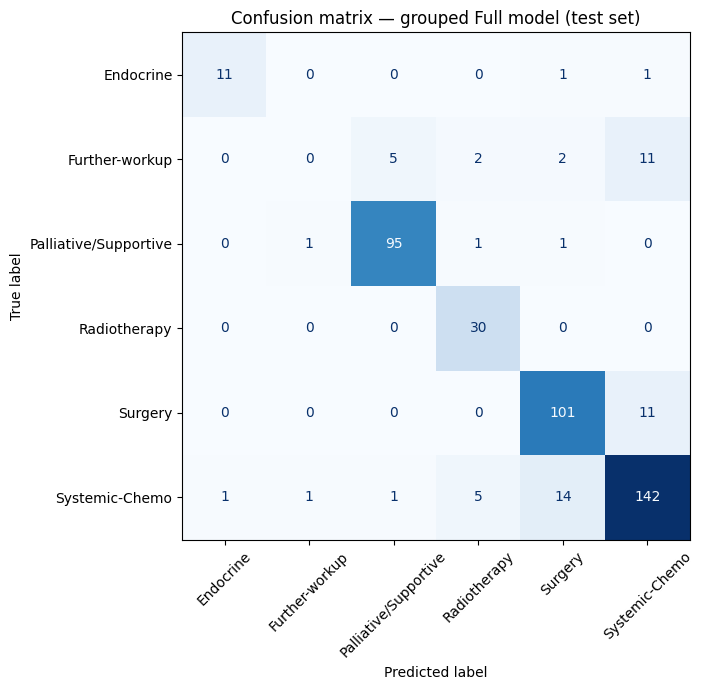

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

data = kath[full_features + [target]].dropna()
X = pd.get_dummies(data[full_features], drop_first=True)
y = data[target].apply(to_supergroup)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=safe_stratify(y))
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=safe_stratify(y_temp))
clf = HistGradientBoostingClassifier(random_state=42).fit(X_train, y_train)
y_pred = clf.predict(X_test)
labels = sorted(y.unique())
print('Per-class performance (grouped Full model):')
print(classification_report(y_test, y_pred, digits=3))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels,
    xticks_rotation=45, cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Confusion matrix — grouped Full model (test set)')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chart_confusion_grouped.png', dpi=150, bbox_inches='tight')
plt.show()


In [63]:
# Lightweight hyperparameter search on the existing validation partition.
# Uses the same train/val/test split already built in the previous cell —
# does not touch or re-split the data, and evaluates the test set exactly once.

from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score

# Small, deliberately lightweight grid — 12 combinations, a few seconds to run
param_grid = [
    {'max_iter': mi, 'learning_rate': lr, 'max_depth': md}
    for mi in [100, 200]
    for lr in [0.05, 0.1, 0.2]
    for md in [None, 8]
]

print(f"Searching {len(param_grid)} configurations on the validation set...\n")

search_results = []
for params in param_grid:
    model = HistGradientBoostingClassifier(random_state=42, **params)
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    val_f1 = f1_score(y_val, val_pred, average='macro')
    search_results.append({**params, 'val_macro_f1': val_f1})

search_df = pd.DataFrame(search_results).sort_values('val_macro_f1', ascending=False)
print("Top 5 configurations by validation macro-F1:")
print(search_df.head(5).to_string(index=False))

# Refit the best configuration and evaluate on the untouched test set, once.
best_params = {k: v for k, v in search_df.iloc[0].items() if k != 'val_macro_f1'}
best_params['max_iter'] = int(best_params['max_iter'])
if best_params['max_depth'] is not None and not pd.isna(best_params['max_depth']):
    best_params['max_depth'] = int(best_params['max_depth'])
else:
    best_params['max_depth'] = None

print(f"\nBest configuration: {best_params}")

best_model = HistGradientBoostingClassifier(random_state=42, **best_params)
best_model.fit(X_train, y_train)
test_pred = best_model.predict(X_test)

print("\n--- Comparison: default HGB vs tuned HGB, on the same test set ---")
print(f"{'Metric':<20}{'Default':>12}{'Tuned':>12}")
default_acc = accuracy_score(y_test, y_pred)          # y_pred is from the cell above (default model)
default_f1 = f1_score(y_test, y_pred, average='macro')
default_bal = balanced_accuracy_score(y_test, y_pred)
tuned_acc = accuracy_score(y_test, test_pred)
tuned_f1 = f1_score(y_test, test_pred, average='macro')
tuned_bal = balanced_accuracy_score(y_test, test_pred)
print(f"{'Accuracy':<20}{default_acc:>12.2%}{tuned_acc:>12.2%}")
print(f"{'Macro-F1':<20}{default_f1:>12.3f}{tuned_f1:>12.3f}")
print(f"{'Balanced accuracy':<20}{default_bal:>12.2%}{tuned_bal:>12.2%}")

Searching 12 configurations on the validation set...

Top 5 configurations by validation macro-F1:
 max_iter  learning_rate  max_depth  val_macro_f1
      200           0.20        NaN      0.743857
      100           0.20        NaN      0.742632
      100           0.20        8.0      0.742480
      100           0.05        8.0      0.742205
      100           0.10        NaN      0.734647

Best configuration: {'max_iter': 200, 'learning_rate': 0.2, 'max_depth': None}

--- Comparison: default HGB vs tuned HGB, on the same test set ---
Metric                   Default       Tuned
Accuracy                  86.73%      86.04%
Macro-F1                   0.742       0.734
Balanced accuracy         76.39%      75.99%


In [64]:
# Per-subgroup performance breakdown, computed from the existing test-set
# predictions — no retraining, just regrouping what the model already predicted.

from sklearn.metrics import f1_score, accuracy_score

# Recover the original (un-encoded) patient-level fields for the test-set rows
test_patients = data.loc[y_test.index].copy()
test_patients['y_true'] = y_test.values
test_patients['y_pred'] = y_pred          # from the confusion-matrix cell above

def subgroup_report(df, group_col, label):
    print(f"\n--- Performance by {label} ---")
    rows = []
    for grp, sub in df.groupby(group_col):
        if len(sub) < 5:      # skip subgroups too small to report meaningfully
            continue
        acc = accuracy_score(sub['y_true'], sub['y_pred'])
        f1 = f1_score(sub['y_true'], sub['y_pred'], average='macro', zero_division=0)
        rows.append({'Group': grp, 'n': len(sub), 'Accuracy': acc, 'Macro-F1': f1})
    out = pd.DataFrame(rows).sort_values('n', ascending=False)
    print(out.to_string(index=False))
    return out

# 1) By disease stage
stage_report = subgroup_report(test_patients, 'AJCC_Stage_Group', 'AJCC stage group')

# 2) By age band
test_patients['Age_Band'] = pd.cut(
    test_patients['Age'], bins=[0, 40, 60, 75, 120],
    labels=['<40', '40-59', '60-74', '75+']
)
age_report = subgroup_report(test_patients, 'Age_Band', 'age band')

# 3) By receptor status (ER and HER2 shown separately)
er_report = subgroup_report(test_patients, 'ER_Status', 'ER status')
her2_report = subgroup_report(test_patients, 'HER2_Status', 'HER2 status')


--- Performance by AJCC stage group ---
    Group   n  Accuracy  Macro-F1
 Stage II 139  0.755396  0.628800
Stage III 133  0.887218  0.745547
 Stage IV  90  0.944444  0.485714
  Stage I  75  0.946667  0.601732

--- Performance by age band ---
Group   n  Accuracy  Macro-F1
40-59 242  0.842975  0.676456
60-74  97  0.907216  0.784354
  <40  67  0.865672  0.725518
  75+  31  0.935484  0.782222

--- Performance by ER status ---
       Group   n  Accuracy  Macro-F1
    Positive 305  0.839344  0.721846
    Negative 120  0.925000  0.754117
Low positive  12  1.000000  1.000000

--- Performance by HER2 status ---
   Group   n  Accuracy  Macro-F1
Negative 351  0.851852  0.733317
Positive  82  0.939024  0.759914


/tmp/ipykernel_1089/2700122320.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for grp, sub in df.groupby(group_col):


## Confusion matrix

Rows = true recommendation. Columns = model's prediction.
The diagonal is correct; everything else is a mistake.

- **Radiotherapy** – 30/30 correct
- **Palliative/Supportive** – 95/98 correct
- **Surgery** – 101/112 correct (11 predicted as chemo)
- **Systemic-Chemo** – 142/164 correct (14 predicted as surgery)
- **Endocrine** – 11/13 correct
- **Further-workup** – 0/20 correct

The surgery/chemo mix-ups are the genuinely borderline cases an MDT would debate.

Further-workup fails completely because it isn't a treatment decision — it means
"we need more information first." That isn't driven by the clinical features the
model sees, so there's nothing to learn from.

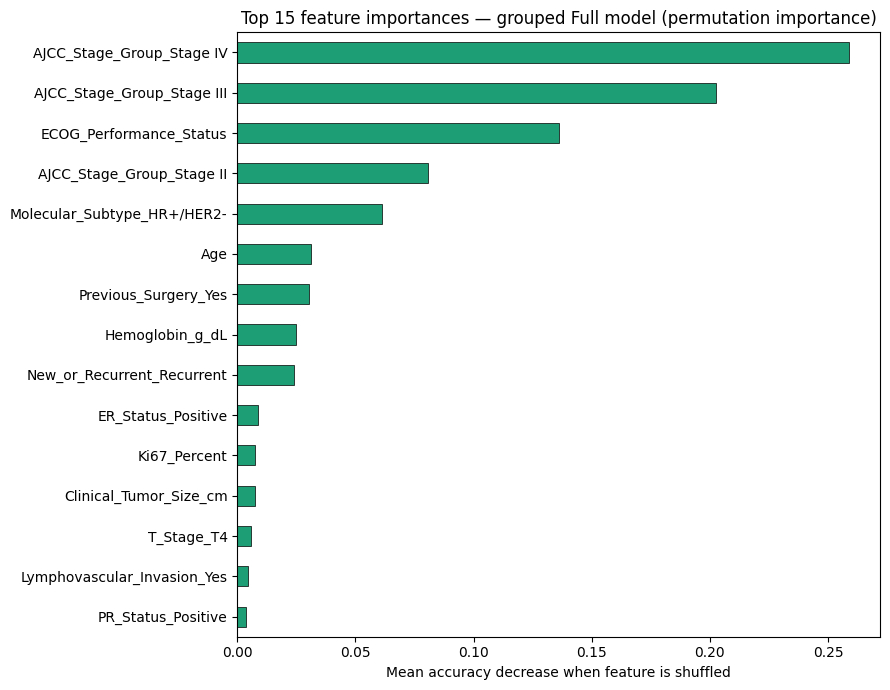

AJCC_Stage_Group_Stage IV      0.259039
AJCC_Stage_Group_Stage III     0.202746
ECOG_Performance_Status        0.135927
AJCC_Stage_Group_Stage II      0.080778
Molecular_Subtype_HR+/HER2-    0.061098
Age                            0.031350
Previous_Surgery_Yes           0.030206
Hemoglobin_g_dL                0.024714
New_or_Recurrent_Recurrent     0.023799
ER_Status_Positive             0.008924
Ki67_Percent                   0.007551
Clinical_Tumor_Size_cm         0.007323
T_Stage_T4                     0.005721
Lymphovascular_Invasion_Yes    0.004348
PR_Status_Positive             0.003661
dtype: float64


In [38]:
from sklearn.inspection import permutation_importance

# Permutation importance: measures how much accuracy drops when a feature's
# values are randomly shuffled. Used instead of the tree's built-in
# feature_importances_, since HistGradientBoosting does not expose one, and
# impurity-based importance is known to be biased toward continuous,
# high-cardinality features (see Section 4.14).
result = permutation_importance(clf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

importances = pd.Series(result.importances_mean, index=X_test.columns).sort_values(ascending=False)
top_n = 15
top_importances = importances.head(top_n)

fig, ax = plt.subplots(figsize=(9, 7))
top_importances.sort_values().plot(kind='barh', ax=ax, color='#1D9E75', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Mean accuracy decrease when feature is shuffled')
ax.set_title(f'Top {top_n} feature importances — grouped Full model (permutation importance)')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chart_feature_importance_grouped.png', dpi=150, bbox_inches='tight')
plt.show()

print(top_importances)

### Calibration: Brier score, expected calibration error, and reliability diagram

Every metric so far measures whether the model picks the right answer.
Calibration measures something different: when the model says it's 99%
confident, is it actually right 99% of the time? A model can discriminate
well and still be badly calibrated, confidently wrong more often than its
stated confidence implies.

Two measures are computed here, built directly rather than through a
library, since neither is available in multi-class form in scikit-learn.
The **multi-class Brier score** compares the model's full probability
vector against the true outcome for every patient. **Expected calibration
error (ECE)** bins predictions by confidence and checks whether stated
confidence matches observed accuracy within each bin.



Multi-class Brier score: 0.226

Bin range        Count  Mean conf.  Observed acc.
--------------------------------------------------
0.4-0.5             2       0.499          0.500
0.5-0.6            12       0.549          0.583
0.6-0.7            11       0.650          0.364
0.7-0.8            15       0.755          0.600
0.8-0.9            14       0.848          0.786
0.9-1.0           383       0.993          0.906

Expected Calibration Error: 0.092
Predictions in the highest confidence bin (0.9-1.0): 383 of 437 (87.6%)


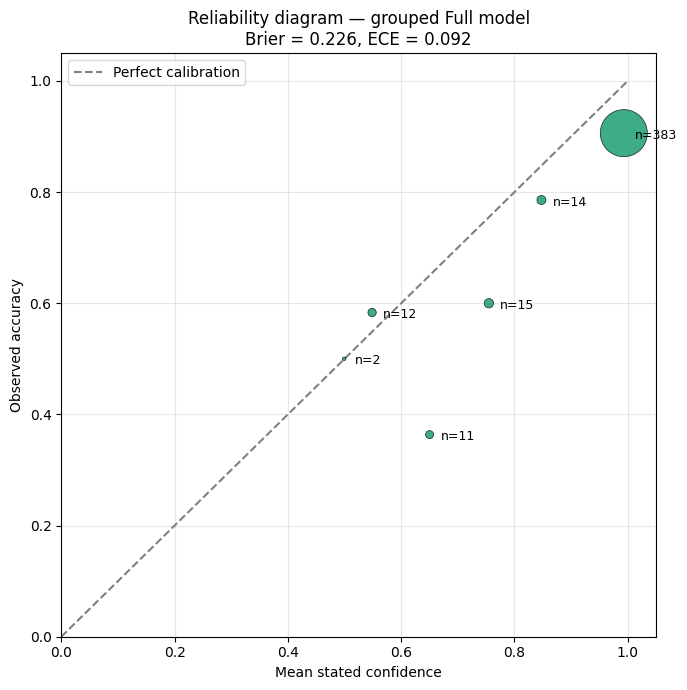

In [39]:
# Calibration assessment on the grouped Full model (same clf, X_test, y_test
# used for the confusion matrix and feature importance above).
import numpy as np

# --- Multi-class Brier score ---
# One-hot encode the true labels in the CLASSIFIER'S OWN class order,
# read from clf.classes_ rather than assumed. Assuming alphabetical or
# insertion order would misalign the columns against predict_proba's
# output and silently produce a meaningless score.
probs = clf.predict_proba(X_test)
class_order = clf.classes_
y_test_onehot = pd.get_dummies(y_test).reindex(columns=class_order, fill_value=0).values

brier = np.mean(np.sum((probs - y_test_onehot) ** 2, axis=1))
print(f"Multi-class Brier score: {brier:.3f}")

# --- Expected Calibration Error (ECE) ---
# Confidence = the probability the model assigned to its own top choice.
# Correct = whether that top choice matched the true label.
confidences = probs.max(axis=1)
predictions = clf.classes_[np.argmax(probs, axis=1)]
correct = (predictions == y_test.values)

n_bins = 10
bin_edges = np.linspace(0, 1, n_bins + 1)
bin_ids = np.digitize(confidences, bin_edges[1:-1])

print()
print(f"{'Bin range':14s} {'Count':>7s} {'Mean conf.':>11s} {'Observed acc.':>14s}")
print("-" * 50)

ece = 0.0
n_total = len(confidences)
for b in range(n_bins):
    in_bin = bin_ids == b
    count = in_bin.sum()
    if count == 0:
        continue  # empty bins carry no calibration information, skip rather than count as zero
    mean_conf = confidences[in_bin].mean()
    obs_acc = correct[in_bin].mean()
    ece += (count / n_total) * abs(mean_conf - obs_acc)
    print(f"{bin_edges[b]:.1f}-{bin_edges[b+1]:.1f}       {count:>7d} {mean_conf:>11.3f} {obs_acc:>14.3f}")

print()
print(f"Expected Calibration Error: {ece:.3f}")
print(f"Predictions in the highest confidence bin (0.9-1.0): {(bin_ids == 9).sum()} of {n_total} "
      f"({(bin_ids == 9).sum()/n_total:.1%})")

# --- Reliability diagram ---
bin_data = []
for b in range(n_bins):
    in_bin = bin_ids == b
    if in_bin.sum() == 0:
        continue
    bin_data.append((confidences[in_bin].mean(), correct[in_bin].mean(), in_bin.sum()))

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
xs, ys, sizes = zip(*bin_data)
scatter = ax.scatter(xs, ys, s=[s * 3 for s in sizes], color='#1D9E75',
                      edgecolor='black', linewidth=0.5, alpha=0.85, zorder=3)
for x, cy, s in bin_data:
    ax.annotate(f'n={s}', (x, cy), textcoords="offset points", xytext=(8, -4), fontsize=9)

ax.set_xlabel('Mean stated confidence')
ax.set_ylabel('Observed accuracy')
ax.set_title(f'Reliability diagram — grouped Full model\nBrier = {brier:.3f}, ECE = {ece:.3f}')
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chart_reliability_diagram.png', dpi=150, bbox_inches='tight')
plt.show()

**5-fold cross-validation** on the grouped Full model, to confirm the headline accuracy is stable across different splits rather than a single lucky split.

In [40]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    HistGradientBoostingClassifier(random_state=42), X, y, cv=cv, scoring='accuracy')
print('5-fold cross-validation (grouped Full model)')
print('-' * 50)
for i, s in enumerate(cv_scores, 1):
    print(f'  Fold {i}: {s:.2%}')
print('-' * 50)
print(f'  Mean accuracy: {cv_scores.mean():.2%}')
print(f'  Std deviation: {cv_scores.std():.2%}')
print(f'\n  Reported result: {cv_scores.mean()*100:.1f}% +/- {cv_scores.std()*100:.1f}%')


5-fold cross-validation (grouped Full model)
--------------------------------------------------
  Fold 1: 87.31%
  Fold 2: 88.49%
  Fold 3: 86.25%
  Fold 4: 87.11%
  Fold 5: 88.83%
--------------------------------------------------
  Mean accuracy: 87.60%
  Std deviation: 0.94%

  Reported result: 87.6% +/- 0.9%


Re-run the Task 2 cross-hospital agreement check using the improved model's predictions.

In [41]:
print("="*60)
print("TASK 2 — CROSS-HOSPITAL TEST")
print("="*60)

# Step 1: Get KATH data with base features
kath_data = kath[base_features + [target]].dropna()
X_kath_raw = kath_data[base_features]
y_kath_all = kath_data[target]

# Step 2: Get SMC data with same features
smc_data = smc_harmonised[base_features].dropna()

# Step 3: Combine FIRST, then encode (so columns match perfectly)
combined = pd.concat([X_kath_raw, smc_data], keys=['kath', 'smc'])
combined_encoded = pd.get_dummies(combined, drop_first=True)
X_kath_encoded = combined_encoded.loc['kath']
X_smc_encoded = combined_encoded.loc['smc']

print(f"After encoding: {X_kath_encoded.shape[1]} columns (consistent across both)")

# Step 4: Do the proper 70/15/15 split on KATH ONLY
X_temp, X_test_k, y_temp, y_test_k = train_test_split(
    X_kath_encoded, y_kath_all, test_size=0.15, random_state=42,
    stratify=safe_stratify(y_kath_all))
X_train_k, X_val_k, y_train_k, y_val_k = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42,
    stratify=safe_stratify(y_temp))

print(f"\nKATH splits:")
print(f"  Train: {len(X_train_k)} patients")
print(f"  Validation: {len(X_val_k)} patients")
print(f"  Test: {len(X_test_k)} patients")
print(f"SMC external: {len(X_smc_encoded)} patients")

# Step 5: Train on KATH training set
print("\nTraining model on KATH training set...")
model_t2 = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)
model_t2.fit(X_train_k, y_train_k)
print("  Done!")

# Step 6: Evaluate
print("\nResults:")
val_acc = accuracy_score(y_val_k, model_t2.predict(X_val_k))
test_acc = accuracy_score(y_test_k, model_t2.predict(X_test_k))
print(f"  KATH validation: {val_acc:.2%}")
print(f"  KATH test:       {test_acc:.2%}")

# Step 7: Predict on SMC
smc_predictions_proper = model_t2.predict(X_smc_encoded)
print(f"\nSMC predictions distribution:")
print(pd.Series(smc_predictions_proper).value_counts())

TASK 2 — CROSS-HOSPITAL TEST
After encoding: 12 columns (consistent across both)

KATH splits:
  Train: 3447 patients
  Validation: 737 patients
  Test: 739 patients
SMC external: 992 patients

Training model on KATH training set...
  Done!

Results:
  KATH validation: 56.72%
  KATH test:       57.10%

SMC predictions distribution:
Neoadjuvant chemotherapy            434
Surgery first - WLE + ANC           257
Surgery first - Mastectomy + ANC    122
Adjuvant chemotherapy                90
Palliative systemic therapy          73
Palliative radiotherapy               7
Neoadjuvant endocrine therapy         6
Adjuvant endocrine therapy            2
Radiotherapy                          1
Name: count, dtype: int64


In [42]:
# Run the agreement check with the proper model's predictions
smc_with_predictions = smc.loc[smc_data.index].copy()
smc_with_predictions['model_prediction'] = smc_predictions_proper

def check_agreement(row):
    model_pred = row['model_prediction']
    chemo = row['mdt_chemo_recommended']
    surgery = row['mdt_surgery_plan']
    rt = row['mdt_rt_recommended']
    intent = row['mdt_intent']

    if model_pred in ['Neoadjuvant chemotherapy', 'Adjuvant chemotherapy']:
        if chemo == 'Y' and surgery in ['Mastectomy', 'BCS']:
            return 'Agree'

    if model_pred == 'Surgery first - Mastectomy + ANC':
        if surgery == 'Mastectomy':
            return 'Agree'

    if model_pred == 'Surgery first - WLE + ANC':
        if surgery == 'BCS':
            return 'Agree'

    if model_pred == 'Palliative systemic therapy':
        if intent == 'Palliative' and chemo == 'Y':
            return 'Agree'

    if model_pred == 'Palliative radiotherapy':
        if intent == 'Palliative' and rt == 'Y':
            return 'Agree'

    if model_pred == 'Best supportive care':
        if intent == 'Palliative' and chemo == 'N':
            return 'Agree'

    if model_pred == 'Radiotherapy':
        if rt == 'Y':
            return 'Agree'

    if model_pred in ['Adjuvant endocrine therapy', 'Neoadjuvant endocrine therapy']:
        if row['mdt_endocrine_recommended'] == 'Y':
            return 'Agree'

    return 'Disagree'

smc_with_predictions['agreement'] = smc_with_predictions.apply(check_agreement, axis=1)

agreement_counts = smc_with_predictions['agreement'].value_counts()
total = len(smc_with_predictions)
agree_count = agreement_counts.get('Agree', 0)

print("="*55)
print("TASK 2 — REFINED CROSS-HOSPITAL AGREEMENT")
print("="*55)
print(f"Model trained on KATH training set (3,447 patients)")
print(f"Tested on SMC ({total} patients) — never seen during training")
print()
print(f"Agreements:    {agree_count}")
print(f"Disagreements: {total - agree_count}")
print(f"AGREEMENT RATE: {agree_count/total:.1%}")

TASK 2 — REFINED CROSS-HOSPITAL AGREEMENT
Model trained on KATH training set (3,447 patients)
Tested on SMC (992 patients) — never seen during training

Agreements:    768
Disagreements: 224
AGREEMENT RATE: 77.4%


### Baseline check: does the agreement rate actually mean anything?

Before trusting the 77.4% agreement rate above, check whether a model
that always predicts the *same* recommendation, regardless of the
patient, scores as well or better under the same agreement rule. If a
constant predictor matches or beats the real model, the agreement rate
cannot be used as evidence of model quality.

In [43]:
# Constant-prediction baseline: replace every model prediction with a
# single fixed category, then re-run the same agreement check, for every
# category the model actually uses.
candidate_predictions = sorted(smc_with_predictions['model_prediction'].unique().tolist())

baseline_results = {}
for const_pred in candidate_predictions:
    test_df = smc_with_predictions.copy()
    test_df['model_prediction'] = const_pred
    test_df['agreement'] = test_df.apply(check_agreement, axis=1)
    rate = (test_df['agreement'] == 'Agree').mean()
    baseline_results[const_pred] = rate

best_constant = max(baseline_results, key=baseline_results.get)
best_rate = baseline_results[best_constant]

print("="*60)
print("BASELINE CHECK: constant-prediction agreement rates")
print("="*60)
for pred, rate in sorted(baseline_results.items(), key=lambda x: -x[1]):
    print(f"  Always '{pred}': {rate:.1%}")
print()
print(f"Best constant predictor: '{best_constant}' at {best_rate:.1%}")
print(f"Actual model agreement rate: {agree_count/total:.1%}")
print(f"Difference (model minus best constant): {agree_count/total - best_rate:+.1%}")

BASELINE CHECK: constant-prediction agreement rates
  Always 'Radiotherapy': 80.2%
  Always 'Adjuvant chemotherapy': 78.4%
  Always 'Neoadjuvant chemotherapy': 78.4%
  Always 'Adjuvant endocrine therapy': 73.6%
  Always 'Neoadjuvant endocrine therapy': 73.6%
  Always 'Surgery first - Mastectomy + ANC': 48.8%
  Always 'Surgery first - WLE + ANC': 43.1%
  Always 'Palliative systemic therapy': 8.1%
  Always 'Palliative radiotherapy': 4.9%

Best constant predictor: 'Radiotherapy' at 80.2%
Actual model agreement rate: 77.4%
Difference (model minus best constant): -2.8%


In [44]:
# Save refined Task 2 results
# Every value is read from the objects computed above (X_train_k,
# agree_count, total), not hand-entered, so the saved table can never
# diverge from the live agreement check.
_agree = int(agree_count)
_total = int(total)
_disagree = _total - _agree

task2_proper = pd.DataFrame({
    'Metric': [
        'Training set (KATH)',
        'SMC patients tested (external)',
        'Agreements with SMC MDT',
        'Disagreements',
        'Cross-hospital agreement rate',
    ],
    'Value': [
        f"{len(X_train_k):,} patients",
        f"{_total:,} patients",
        f"{_agree:,}",
        f"{_disagree:,}",
        f"{_agree/_total:.1%}",
    ]
})

task2_proper.to_excel('/content/drive/MyDrive/results_task2_proper.xlsx', index=False)
print("Refined Task 2 results saved (values derived from agreement check):")
print(task2_proper.to_string(index=False))

Refined Task 2 results saved (values derived from agreement check):
                        Metric          Value
           Training set (KATH) 3,447 patients
SMC patients tested (external)   992 patients
       Agreements with SMC MDT            768
                 Disagreements            224
 Cross-hospital agreement rate          77.4%


In [45]:
print("="*60)
print("TASK 3 — KATH MODEL TESTED ON SEER (US DATA)")
print("="*60)

# Use 4 features (SEER doesn't have HER2)
seer_features = ['Age', 'AJCC_Stage_Group', 'ER_Status', 'PR_Status']

# Step 1: Prepare KATH and SEER data
kath_seer_data = kath[seer_features + [target]].dropna()
X_kath_raw = kath_seer_data[seer_features]
y_kath_all = kath_seer_data[target]

X_seer_raw = seer_harmonised[seer_features].dropna()

# Step 2: Combine first, then encode (so columns match)
combined = pd.concat([X_kath_raw, X_seer_raw], keys=['kath', 'seer'])
combined_encoded = pd.get_dummies(combined, drop_first=True)
X_kath_encoded = combined_encoded.loc['kath']
X_seer_encoded = combined_encoded.loc['seer']

print(f"After encoding: {X_kath_encoded.shape[1]} columns")

# Step 3: 70/15/15 split on KATH
X_temp, X_test_k, y_temp, y_test_k = train_test_split(
    X_kath_encoded, y_kath_all, test_size=0.15, random_state=42,
    stratify=safe_stratify(y_kath_all))
X_train_k, X_val_k, y_train_k, y_val_k = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42,
    stratify=safe_stratify(y_temp))

print(f"\nKATH splits:")
print(f"  Train: {len(X_train_k)} patients")
print(f"  Validation: {len(X_val_k)} patients")
print(f"  Test: {len(X_test_k)} patients")
print(f"SEER external: {len(X_seer_encoded)} patients")

# Step 4: Train on KATH training set
print("\nTraining model on KATH training set...")
model_t3 = RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)
model_t3.fit(X_train_k, y_train_k)
print("  Done!")

# Step 5: Evaluate
val_acc = accuracy_score(y_val_k, model_t3.predict(X_val_k))
test_acc = accuracy_score(y_test_k, model_t3.predict(X_test_k))
print(f"\nResults:")
print(f"  KATH validation: {val_acc:.2%}")
print(f"  KATH test:       {test_acc:.2%}")

# Step 6: Predict on SEER
seer_predictions = model_t3.predict(X_seer_encoded)
print(f"\nSEER predictions distribution:")
print(pd.Series(seer_predictions).value_counts())

TASK 3 — KATH MODEL TESTED ON SEER (US DATA)
After encoding: 9 columns

KATH splits:
  Train: 3447 patients
  Validation: 737 patients
  Test: 739 patients
SEER external: 4024 patients

Training model on KATH training set...
  Done!

Results:
  KATH validation: 54.00%
  KATH test:       54.26%

SEER predictions distribution:
Neoadjuvant chemotherapy            1823
Surgery first - Mastectomy + ANC     955
Surgery first - WLE + ANC            611
Adjuvant chemotherapy                598
Radiotherapy                          35
Further imaging required               2
Name: count, dtype: int64


In [46]:
# Bring back SEER survival data
seer_with_predictions = seer.loc[X_seer_raw.index].copy()
seer_with_predictions['model_prediction'] = seer_predictions

# Group predictions into broader categories
def simplify(pred):
    if 'chemotherapy' in pred.lower():
        return 'Chemotherapy'
    elif 'surgery' in pred.lower():
        return 'Surgery first'
    else:
        return 'Other'

seer_with_predictions['rec_group'] = seer_with_predictions['model_prediction'].apply(simplify)

print("="*65)
print("TASK 3 — SURVIVAL OUTCOMES BY MODEL RECOMMENDATION")
print("="*65)

for group in ['Surgery first', 'Chemotherapy']:
    subset = seer_with_predictions[seer_with_predictions['rec_group'] == group]
    n = len(subset)
    avg_survival = subset['Survival Months'].mean()
    alive_pct = (subset['Status'] == 'Alive').mean() * 100

    print(f"\n{group}:")
    print(f"  Number of patients: {n}")
    print(f"  Average survival: {avg_survival:.1f} months")
    print(f"  Still alive at follow-up: {alive_pct:.1f}%")

# Statistical significance test
from scipy.stats import chi2_contingency
ct = pd.crosstab(seer_with_predictions['rec_group'], seer_with_predictions['Status'])
print("\n" + "="*65)
print("STATISTICAL TEST")
print("="*65)
print("\nContingency table:")
print(ct)

chi2, p_value, dof, expected = chi2_contingency(ct)
print(f"\nChi-square: {chi2:.2f}")
print(f"p-value: {p_value:.2e}")

if p_value < 0.001:
    print("\n*** Highly statistically significant (p < 0.001) ***")

TASK 3 — SURVIVAL OUTCOMES BY MODEL RECOMMENDATION

Surgery first:
  Number of patients: 1566
  Average survival: 73.6 months
  Still alive at follow-up: 91.7%

Chemotherapy:
  Number of patients: 2421
  Average survival: 69.9 months
  Still alive at follow-up: 80.3%

STATISTICAL TEST

Contingency table:
Status         Alive  Dead
rec_group                 
Chemotherapy    1944   477
Other             28     9
Surgery first   1436   130

Chi-square: 97.68
p-value: 6.15e-22

*** Highly statistically significant (p < 0.001) ***


### Stratify by disease stage

Disease stage plausibly drives both the model's recommendation and
survival outcome, so the association above may just be measuring stage,
not the model. Repeat the same test within each stage separately: if
the association survives, it is not purely a stage confound.

In [47]:
# Stage-stratified significance test, restricted to Chemotherapy vs Surgery
# first, matching the two-category comparison reported in the dissertation.
# The residual 'Other' category (predictions outside these two groups) is
# excluded here, since it represents a handful of patients and is not part
# of the surgery-vs-chemo comparison being tested.
from scipy.stats import chi2_contingency

seer_with_predictions['AJCC_Stage_Group'] = seer_harmonised.loc[X_seer_raw.index, 'AJCC_Stage_Group']

print("="*65)
print("TASK 3 — STAGE-STRATIFIED SIGNIFICANCE TEST")
print("="*65)

for stage in ['Stage II', 'Stage III']:
    stage_subset = seer_with_predictions[
        (seer_with_predictions['AJCC_Stage_Group'] == stage) &
        (seer_with_predictions['rec_group'] != 'Other')
    ]
    print(f"\n{stage} (n={len(stage_subset)}):")
    ct_stage = pd.crosstab(stage_subset['rec_group'], stage_subset['Status'])
    print(ct_stage)
    ct_pct = pd.crosstab(stage_subset['rec_group'], stage_subset['Status'], normalize='index') * 100
    print(ct_pct.round(1))

    group_pct = stage_subset['rec_group'].value_counts(normalize=True) * 100
    print("  Treatment group split:", dict(group_pct.round(1)))

    try:
        chi2_s, p_s, dof_s, expected_s = chi2_contingency(ct_stage)
        print(f"  Chi-square: {chi2_s:.2f}, p-value: {p_s:.3g}")
    except ValueError as e:
        print(f"  Could not run test (likely insufficient variation): {e}")

TASK 3 — STAGE-STRATIFIED SIGNIFICANCE TEST

Stage II (n=2433):
Status         Alive  Dead
rec_group                 
Chemotherapy     767   100
Surgery first   1436   130
Status         Alive  Dead
rec_group                 
Chemotherapy    88.5  11.5
Surgery first   91.7   8.3
  Treatment group split: {'Surgery first': np.float64(64.4), 'Chemotherapy': np.float64(35.6)}
  Chi-square: 6.44, p-value: 0.0112

Stage III (n=1554):
Status        Alive  Dead
rec_group                
Chemotherapy   1177   377
Status        Alive  Dead
rec_group                
Chemotherapy   75.7  24.3
  Treatment group split: {'Chemotherapy': np.float64(100.0)}
  Chi-square: 0.00, p-value: 1


Save the Task 3 SEER validation results.

In [48]:
# Save Task 3 results
# Values are computed from seer_with_predictions and the chi-square test
# above, not typed as literals.
_rows = []
for group in ['Surgery first', 'Chemotherapy']:
    sub = seer_with_predictions[seer_with_predictions['rec_group'] == group]
    _rows.append({
        'Group': group,
        'Patients': int(len(sub)),
        'Avg survival (months)': round(sub['Survival Months'].mean(), 1),
        'Alive at follow-up (%)': round((sub['Status'] == 'Alive').mean() * 100, 1),
        'Death rate (%)': round((sub['Status'] != 'Alive').mean() * 100, 1),
    })
task3_final = pd.DataFrame(_rows)

task3_final.to_excel('/content/drive/MyDrive/results_task3_seer.xlsx', index=False)
print("Task 3 results saved (values derived from seer_with_predictions):")
print(task3_final.to_string(index=False))
print(f"\nStatistical significance: chi-square = {chi2:.2f}, p = {p_value:.2e}")

Task 3 results saved (values derived from seer_with_predictions):
        Group  Patients  Avg survival (months)  Alive at follow-up (%)  Death rate (%)
Surgery first      1566                   73.6                    91.7             8.3
 Chemotherapy      2421                   69.9                    80.3            19.7

Statistical significance: chi-square = 97.68, p = 6.15e-22


In [49]:
# Section 5.5.1: Population relatedness (membership-model AUC) and
# residual shift (Population Stability Index), matching the design
# described in Section 3.8 / Table 3.3.

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

def membership_auc(dev_df, val_df, shared_cols, seed=42):
    """Binary classifier distinguishing development (KATH) from receiving-site
    patients on shared covariates only. AUC near 0.5 = indistinguishable;
    near 1.0 = extrapolation."""
    dev_sub = dev_df[shared_cols].dropna()
    val_sub = val_df[shared_cols].dropna()
    combined = pd.concat([dev_sub, val_sub], keys=['dev', 'val'])
    combined_encoded = pd.get_dummies(combined, drop_first=True)
    y_source = np.array([0]*len(dev_sub) + [1]*len(val_sub))
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    model = RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1)
    probs = cross_val_predict(model, combined_encoded, y_source, cv=cv,
                               method='predict_proba')[:, 1]
    return roc_auc_score(y_source, probs)

def calculate_psi(dev_series, val_series, bins=10, epsilon=1e-6):
    """Population Stability Index for one variable. Continuous variables are
    binned by quantiles from the DEVELOPMENT (KATH) distribution; categorical
    variables use the union of categories observed at both sites."""
    dev = dev_series.dropna()
    val = val_series.dropna()
    if dev.dtype == object or dev.dtype.name == 'category':
        categories = sorted(set(dev.astype(str).unique()) | set(val.astype(str).unique()))
        dev_props = dev.astype(str).value_counts(normalize=True).reindex(categories, fill_value=0)
        val_props = val.astype(str).value_counts(normalize=True).reindex(categories, fill_value=0)
    else:
        edges = dev.quantile(np.linspace(0, 1, bins + 1)).values
        edges = np.unique(edges)
        edges[0], edges[-1] = -np.inf, np.inf
        dev_binned = pd.cut(dev, bins=edges, duplicates='drop')
        val_binned = pd.cut(val, bins=edges, duplicates='drop')
        dev_props = dev_binned.value_counts(normalize=True, sort=False)
        val_props = val_binned.value_counts(normalize=True, sort=False)
    dev_props = dev_props.clip(lower=epsilon)
    val_props = val_props.reindex(dev_props.index, fill_value=0).clip(lower=epsilon)
    return float(np.sum((val_props - dev_props) * np.log(val_props / dev_props)))

print("="*60)
print("MEMBERSHIP-MODEL AUC (population relatedness)")
print("="*60)
auc_sgmc = membership_auc(kath, smc_harmonised, base_features)
auc_seer = membership_auc(kath, seer_harmonised, seer_features)
print(f"KATH vs SGMC membership AUC: {auc_sgmc:.3f}")
print(f"KATH vs SEER membership AUC: {auc_seer:.3f}")

print()
print("="*60)
print("POPULATION STABILITY INDEX — KATH vs SGMC (base_features)")
print("="*60)
for col in base_features:
    psi = calculate_psi(kath[col], smc_harmonised[col])
    print(f"  {col:20s}: PSI = {psi:.3f}")

print()
print("="*60)
print("POPULATION STABILITY INDEX — KATH vs SEER (seer_features)")
print("="*60)
for col in seer_features:
    psi = calculate_psi(kath[col], seer_harmonised[col])
    print(f"  {col:20s}: PSI = {psi:.3f}")

MEMBERSHIP-MODEL AUC (population relatedness)
KATH vs SGMC membership AUC: 0.655
KATH vs SEER membership AUC: 0.857

POPULATION STABILITY INDEX — KATH vs SGMC (base_features)
  Age                 : PSI = 0.047
  AJCC_Stage_Group    : PSI = 0.219
  ER_Status           : PSI = 0.344
  PR_Status           : PSI = 0.084
  HER2_Status         : PSI = 0.364

POPULATION STABILITY INDEX — KATH vs SEER (seer_features)
  Age                 : PSI = 1.362
  AJCC_Stage_Group    : PSI = 5.017
  ER_Status           : PSI = 1.227
  PR_Status           : PSI = 0.852


### RAG setup

Installing the tools needed: one to read PDFs, one to search for
relevant text, one to generate explanations.

In [50]:
!pip install -q sentence-transformers pypdf transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 388.1/388.1 kB 10.7 MB/s eta 0:00:00


### Load the guideline

Reading the NICE PDF and cutting it into small, overlapping pieces
(chunks). Small pieces are easier to search through than one giant
document.

In [51]:
import re

# UPDATE THIS to your actual Drive file path
GUIDELINE_PDF = '/content/drive/MyDrive/NICE guideline.pdf/NICE.pdf'
GUIDELINE_CITATION = "NICE Guideline NG101, Early and Locally Advanced Breast Cancer: Diagnosis and Management (2018, updated 2025)"

from pypdf import PdfReader

def load_guideline(pdf_path):
    reader = PdfReader(pdf_path)
    return [{'page': i + 1, 'text': (p.extract_text() or '')}
            for i, p in enumerate(reader.pages)]

def chunk_pages(pages, target_words=180, overlap=40, min_real_words=30):
    chunks = []
    for p in pages:
        words = re.sub(r'\s+', ' ', p['text']).split()
        if not words:
            continue
        step = target_words - overlap
        for start in range(0, len(words), step):
            piece = words[start:start + target_words]
            if len(piece) < 20:
                continue
            text = ' '.join(piece)
            real_words = [w for w in piece if w.lower() not in
                         ('nice', '2026', 'rights', 'reserved', 'page', 'notice', 'terms', 'conditions')]
            if len(real_words) < min_real_words:
                continue
            chunks.append({'page': p['page'], 'text': text})
    return chunks

guideline_pages = load_guideline(GUIDELINE_PDF)
guideline_chunks = chunk_pages(guideline_pages)
print(f"Loaded {GUIDELINE_CITATION}")
print(f"{len(guideline_pages)} pages -> {len(guideline_chunks)} chunks")

Loaded NICE Guideline NG101, Early and Locally Advanced Breast Cancer: Diagnosis and Management (2018, updated 2025)
108 pages -> 232 chunks


### Build the search tool

Turning every chunk into a set of numbers (an "embedding") that
captures its meaning. Later, we compare a question's numbers against
every chunk's numbers to find the closest match, like a smart search.

Runs on CPU, no GPU needed for this part.

In [52]:
from sentence_transformers import SentenceTransformer
import numpy as np

embed_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

chunk_texts = [c['text'] for c in guideline_chunks]
chunk_embeddings = embed_model.encode(chunk_texts, show_progress_bar=True, normalize_embeddings=True)
chunk_embeddings = np.asarray(chunk_embeddings)

def retrieve(query, k=4):
    q = embed_model.encode([query], normalize_embeddings=True)[0]
    sims = chunk_embeddings @ q
    top = np.argsort(sims)[::-1][:k]
    return [{**guideline_chunks[i], 'score': float(sims[i])} for i in top]

# quick check
demo = retrieve("HER2 positive breast cancer chemotherapy", k=2)
print(f"Top match: page {demo[0]['page']}, score {demo[0]['score']:.3f}")
print(demo[0]['text'][:200])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Top match: page 28, score 0.759
positive, HER2-negative breast cancer and adjuvant chemotherapy. Adjuvant treatment of BRCA-mutation-positive HER2-negative breast cancer 1.10.3 Olaparib, alone or with endocrine therapy, is recommend


### Load the explanation model

A small AI model that will write the explanation. Small enough to run
on Colab's free GPU (make sure Runtime -> GPU is turned on).

In [53]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

GEN_MODEL = 'Qwen/Qwen2.5-1.5B-Instruct'

tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model = AutoModelForCausalLM.from_pretrained(
    GEN_MODEL,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map='auto')
print(f"Loaded {GEN_MODEL} on {'GPU' if torch.cuda.is_available() else 'CPU'}")

def generate(prompt, max_new_tokens=600):
    messages = [{'role': 'user', 'content': prompt}]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors='pt').to(gen_model.device)
    with torch.no_grad():
        out = gen_model.generate(**inputs, max_new_tokens=max_new_tokens,
                                 do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True).strip()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct on GPU


### Explain a recommendation

For one patient: take the model's prediction, search the guideline for
relevant passages, and have the AI write an explanation using only
what it found, with page numbers so you can check it.

In [54]:
def build_prompt(recommendation, patient_dict, retrieved):
    context = "\n\n".join(f"[Page {c['page']}]\n{c['text']}" for c in retrieved)
    patient_str = '\n'.join(f"{k}: {v}" for k, v in patient_dict.items())

    return f"""You are assisting a breast cancer multidisciplinary team. A validated
machine-learning model recommended the following management. You are NOT deciding
treatment. You are explaining what the retrieved guideline text says that relates
to this recommendation.

CRITICAL RULE: The retrieved passages may discuss a treatment category in general.
This does NOT mean the guideline has confirmed that treatment is appropriate for
THIS specific patient. Never write a sentence stating or implying that NICE
"supports", "confirms", or "indicates" the recommendation is correct for this
patient. You may only state what the retrieved text itself says.

OTHER RULES:
- Use ONLY the patient details given below. Never mention any detail not listed
  here (no treatment history, no prior therapies, nothing invented).
- Use ONLY the guideline passages given below. Never cite a page not shown here.
- Quote or closely paraphrase the retrieved text; do not draw a new clinical
  conclusion that is not explicitly stated in it.

Patient Characteristics: {patient_str}
ML Prediction: {recommendation}

Retrieved NICE passages:
{context}

Write your answer in exactly this structure, with these five headings:

Patient Characteristics:
[restate the patient values exactly as given above, nothing more]

ML Prediction:
[restate the prediction exactly as given above, nothing more]

Relevant NICE Recommendations:
[summarise only what the retrieved passages above actually say, in 1-3 sentences]

Evidence-Based Interpretation:
[state only what the retrieved passages explicitly support about this treatment
category in general. Do NOT claim the guideline validates this prediction for
this specific patient.]

Limitations:
[state plainly that the retrieved guidance does not by itself establish that this
treatment is indicated for this individual patient, since that requires factors
(such as tumour grade, nodal status, or a full multidisciplinary assessment) not
captured in the five characteristics available to the model. Do not invent any
patient history.]"""

In [55]:
def check_patient_consistency(explanation, patient_dict):
    issues = []
    low = explanation.lower()
    status_fields = {'ER_Status': 'ER', 'PR_Status': 'PR', 'HER2_Status': 'HER2'}
    for field, short_name in status_fields.items():
        if field not in patient_dict:
            continue
        real_value = patient_dict[field].lower()
        wrong_value = 'negative' if real_value == 'positive' else 'positive'
        pattern = rf'\b{wrong_value}\b[^.]{{0,40}}\b{short_name.lower()}\b|\b{short_name.lower()}\b[^.]{{0,40}}\b{wrong_value}\b'
        if re.search(pattern, low):
            issues.append(f"Explanation may state {short_name} as {wrong_value}, but patient is {real_value}")
    return issues

print("check_patient_consistency restored")

check_patient_consistency restored


In [56]:
import pandas as pd

_data_full = kath[full_features + [target]].dropna()
patients_test = _data_full.loc[X_test.index].reset_index(drop=True)

KEY_FIELDS = [f for f in ['Age', 'AJCC_Stage_Group', 'ER_Status', 'PR_Status', 'HER2_Status']
              if f in full_features]

def describe_patient(row):
    return ", ".join(f"{f.replace('_',' ')}: {row[f]}" for f in KEY_FIELDS if f in row)

def patient_dict_from_row(row):
    return {f: row[f] for f in KEY_FIELDS if f in row}

def explain(i, k=5, show=True):
    recommendation = y_pred[i]
    row = patients_test.iloc[i]
    patient_dict = patient_dict_from_row(row)

    query = f"Breast cancer management: {recommendation}. Patient: {describe_patient(row)}."
    retrieved = retrieve(query, k=k)
    prompt = build_prompt(recommendation, patient_dict, retrieved)
    explanation = generate(prompt)
    consistency_issues = check_patient_consistency(explanation, patient_dict)

    if show:
        print(f"Patient {i}: {describe_patient(row)}")
        print(f"Recommendation: {recommendation}")
        print(f"Explanation:\n{explanation}")
        if consistency_issues:
            print(f"CONSISTENCY WARNING: {consistency_issues}")
        print()
    return {'patient': i, 'recommendation': recommendation, 'pages': [c['page'] for c in retrieved],
            'explanation': explanation, 'retrieved': retrieved, 'consistency_issues': consistency_issues}

for i in range(3):
    explain(i)
    print('-' * 60)

Patient 0: Age: 38, AJCC Stage Group: Stage II, ER Status: Positive, PR Status: Positive, HER2 Status: Negative
Recommendation: Radiotherapy
Explanation:
**Patient Characteristics:** Age: 38  
AJCC_Stage_Group: Stage II  
ER_Status: Positive  
PR_Status: Positive  
HER2_Status: Negative  
ML Prediction: Radiotherapy  

**Relevant NICE Recommendations:**  
The retrieved NICE passages indicate that for patients with positive ER and PR statuses and negative HER2 status, early and locally advanced breast cancer, including those who have undergone breast-conserving surgery with clear margins, should be considered for partial-breast radiotherapy as an alternative to whole-breast radiotherapy. This recommendation is based on the availability of ER, PR, and HER2 statuses during multidisciplinary discussions and the consideration of low absolute risk of local recurrence among certain age groups and tumor characteristics.

**Evidence-Based Interpretation:**  
The retrieved NICE passage supports 

### Check the results

Two checks, run across 30 patients:

Concordance: does the model's recommendation actually match what the
guideline says for that patient?

Faithfulness: does the explanation stick to what the guideline
actually said, or did the AI make something up?

In [57]:
import collections
print("collections imported")

collections imported


In [58]:
def concordance_label(result):
    rec = result['recommendation'].lower()
    corpus = " ".join(c['text'].lower() for c in result['retrieved'])
    keymap = {
        'systemic': ['chemotherapy', 'systemic', 'trastuzumab'],
        'surgery': ['surgery', 'mastectomy', 'excision'],
        'radiotherapy': ['radiation', 'radiotherapy'],
        'endocrine': ['endocrine', 'tamoxifen', 'aromatase'],
        'palliative': ['palliative', 'supportive'],
    }
    for key, kws in keymap.items():
        if key in rec:
            return 'AGREE' if any(kw in corpus for kw in kws) else 'UNCLEAR'
    return 'UNCLEAR'

print("concordance_label restored")

concordance_label restored


In [59]:
sample_n = min(30, len(y_pred))
results = [explain(i, k=5, show=False) for i in range(sample_n)]

conc = collections.Counter(concordance_label(r) for r in results)
print(f"Tested {sample_n} patients")
print(f"Concordance: {dict(conc)}")
print()

for r in results:
    print(f"Patient {r['patient']}: {r['recommendation']}")
    print(r['explanation'])
    if r['consistency_issues']:
        print(f"[Automated flag, may be a false alarm: {r['consistency_issues']}]")
    print('-' * 60)

Tested 30 patients
Concordance: {'AGREE': 16, 'UNCLEAR': 14}

Patient 0: Radiotherapy
**Patient Characteristics:** Age: 38  
AJCC_Stage_Group: Stage II  
ER_Status: Positive  
PR_Status: Positive  
HER2_Status: Negative  
ML Prediction: Radiotherapy  

**Relevant NICE Recommendations:**  
The retrieved NICE passages indicate that for patients with positive ER and PR statuses and negative HER2 status, early and locally advanced breast cancer, including those who have undergone breast-conserving surgery with clear margins, should be considered for partial-breast radiotherapy as an alternative to whole-breast radiotherapy. This recommendation is based on the availability of ER, PR, and HER2 statuses during multidisciplinary discussions and the consideration of low absolute risk of local recurrence among certain age groups and tumor characteristics.

**Evidence-Based Interpretation:**  
The retrieved NICE passage supports the use of partial-breast radiotherapy as an alternative to whole-br

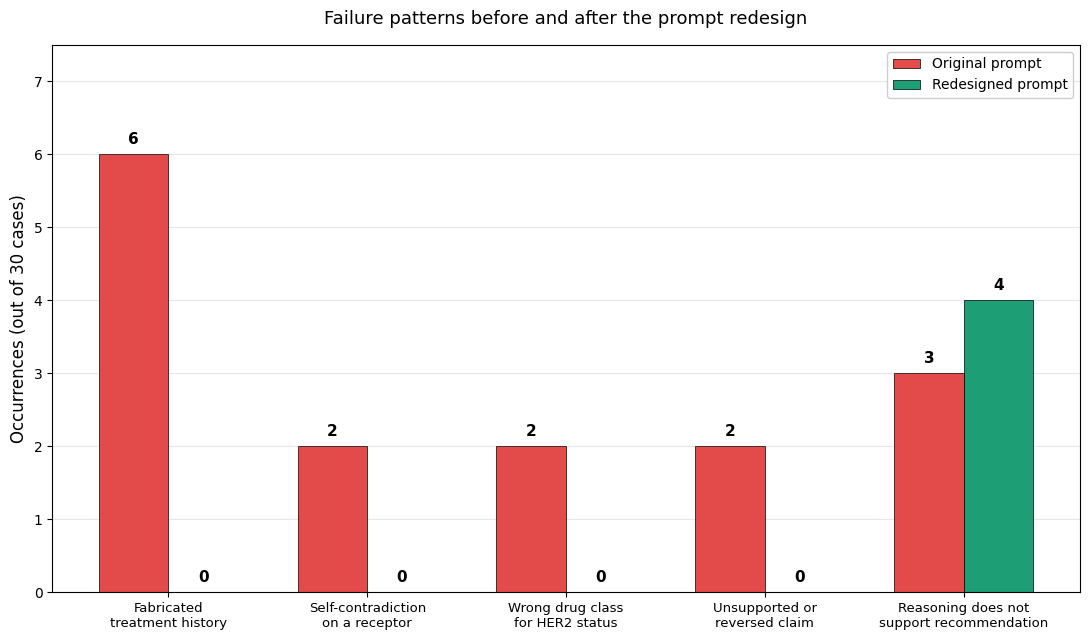

Figure 5 saved: chart_rag_before_after.png


In [60]:
# Figure 5: failure-pattern counts before and after the prompt redesign,
# corresponding directly to Table 5.6.
import numpy as np

patterns = [
    'Fabricated\ntreatment history',
    'Self-contradiction\non a receptor',
    'Wrong drug class\nfor HER2 status',
    'Unsupported or\nreversed claim',
    'Reasoning does not\nsupport recommendation',
]
original_prompt = [6, 2, 2, 2, 3]
redesigned_prompt = [0, 0, 0, 0, 4]

x = np.arange(len(patterns))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6.5))
bars1 = ax.bar(x - width/2, original_prompt, width, label='Original prompt',
               color='#E24B4A', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, redesigned_prompt, width, label='Redesigned prompt',
               color='#1D9E75', edgecolor='black', linewidth=0.5)

for bars in (bars1, bars2):
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.1, f'{int(height)}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('Occurrences (out of 30 cases)', fontsize=12)
ax.set_title('Failure patterns before and after the prompt redesign', fontsize=13, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(patterns, fontsize=9.5)
ax.set_ylim(0, 7.5)
ax.legend(loc='upper right', framealpha=0.95)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/chart_rag_before_after.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 5 saved: chart_rag_before_after.png")

### Worked example: one patient, start to finish

Enter a patient's details, get the model's prediction, then get the
AI's explanation grounded in the guideline. Shows the whole system
working end to end on one concrete case.

In [61]:
def run_full_pipeline(patient_dict):
    """
    Takes patient details, runs them through the classifier,
    then generates a guideline-grounded explanation.
    """
    patient_row = pd.DataFrame([patient_dict])
    patient_encoded = pd.get_dummies(patient_row)
    patient_encoded = patient_encoded.reindex(columns=X_test.columns, fill_value=0)

    prediction = clf.predict(patient_encoded)[0]

    query = f"Breast cancer management: {prediction}. Patient: {', '.join(f'{k}: {v}' for k, v in patient_dict.items())}."
    retrieved = retrieve(query, k=5)
    prompt = build_prompt(prediction, patient_dict, retrieved)
    explanation = generate(prompt)

    consistency_issues = check_patient_consistency(explanation, patient_dict)

    print("Input:")
    for k, v in patient_dict.items():
        print(f"  {k}: {v}")
    print(f"\nML Prediction:\n  {prediction}")
    print(f"\nGuideline-grounded explanation:\n  {explanation}")
    if consistency_issues:
        print(f"\nCONSISTENCY WARNING:")
        for issue in consistency_issues:
            print(f"  {issue}")

    return prediction, explanation, consistency_issues


example_patient = {
    'Age': 45,
    'AJCC_Stage_Group': 'Stage II',
    'ER_Status': 'Negative',
    'PR_Status': 'Negative',
    'HER2_Status': 'Negative',
}

run_full_pipeline(example_patient)

Input:
  Age: 45
  AJCC_Stage_Group: Stage II
  ER_Status: Negative
  PR_Status: Negative
  HER2_Status: Negative

ML Prediction:
  Systemic-Chemo

Guideline-grounded explanation:
  **Patient Characteristics:** Age: 45  
AJCC_Stage_Group: Stage II  
ER_Status: Negative  
PR_Status: Negative  
HER2_Status: Negative  
ML Prediction: Systemic-Chemo  

**Relevant NICE Recommendations:**  
The retrieved NICE passages indicate that for patients with positive hormone receptor-positive, HER2-negative early breast cancer, adjuvant treatment options include olaparib, alone or with endocrine therapy, which is recommended as an option for Early and locally advanced breast cancer: diagnosis and management (NG101), subject to certain guidelines and recommendations. However, the passage does not specify whether this treatment is applicable to all stages or specifically to Stage II cancers based solely on the provided information.

**Evidence-Based Interpretation:**  
The retrieved NICE passages sugge

('Systemic-Chemo',
 '**Patient Characteristics:** Age: 45  \nAJCC_Stage_Group: Stage II  \nER_Status: Negative  \nPR_Status: Negative  \nHER2_Status: Negative  \nML Prediction: Systemic-Chemo  \n\n**Relevant NICE Recommendations:**  \nThe retrieved NICE passages indicate that for patients with positive hormone receptor-positive, HER2-negative early breast cancer, adjuvant treatment options include olaparib, alone or with endocrine therapy, which is recommended as an option for Early and locally advanced breast cancer: diagnosis and management (NG101), subject to certain guidelines and recommendations. However, the passage does not specify whether this treatment is applicable to all stages or specifically to Stage II cancers based solely on the provided information.\n\n**Evidence-Based Interpretation:**  \nThe retrieved NICE passages suggest that for patients with positive hormone receptor-positive, HER2-negative early breast cancer, adjuvant treatment options such as olaparib might be 

### More worked examples

Testing a handful of different patient profiles to see how the system
behaves across different cases, not just one.

In [62]:
example_patients = [
    {
        'Age': 45, 'AJCC_Stage_Group': 'Stage II',
        'ER_Status': 'Negative', 'PR_Status': 'Negative', 'HER2_Status': 'Negative',
    },  # triple-negative, already tested
    {
        'Age': 62, 'AJCC_Stage_Group': 'Stage I',
        'ER_Status': 'Positive', 'PR_Status': 'Positive', 'HER2_Status': 'Negative',
    },  # hormone-positive, early stage, common profile
    {
        'Age': 50, 'AJCC_Stage_Group': 'Stage III',
        'ER_Status': 'Negative', 'PR_Status': 'Negative', 'HER2_Status': 'Positive',
    },  # HER2-positive, more advanced
    {
        'Age': 70, 'AJCC_Stage_Group': 'Stage IV',
        'ER_Status': 'Positive', 'PR_Status': 'Positive', 'HER2_Status': 'Negative',
    },  # advanced stage, hormone-positive
    {
        'Age': 38, 'AJCC_Stage_Group': 'Stage II',
        'ER_Status': 'Positive', 'PR_Status': 'Negative', 'HER2_Status': 'Positive',
    },  # mixed receptor profile
]

all_examples = []
for i, patient in enumerate(example_patients):
    print(f"{'='*70}")
    print(f"EXAMPLE {i+1}")
    print('='*70)
    prediction, explanation, consistency_issues = run_full_pipeline(patient)
    all_examples.append({'patient': patient, 'prediction': prediction, 'explanation': explanation})
    print()

EXAMPLE 1
Input:
  Age: 45
  AJCC_Stage_Group: Stage II
  ER_Status: Negative
  PR_Status: Negative
  HER2_Status: Negative

ML Prediction:
  Systemic-Chemo

Guideline-grounded explanation:
  **Patient Characteristics:** Age: 45  
AJCC_Stage_Group: Stage II  
ER_Status: Negative  
PR_Status: Negative  
HER2_Status: Negative  
ML Prediction: Systemic-Chemo  

**Relevant NICE Recommendations:**  
The retrieved NICE passages indicate that for patients with positive hormone receptor-positive, HER2-negative early breast cancer, adjuvant treatment options include olaparib, alone or with endocrine therapy, which is recommended as an option for Early and locally advanced breast cancer: diagnosis and management (NG101), subject to certain guidelines and recommendations. However, the passage does not specify whether this treatment is applicable to all stages or specifically to Stage II cancers based solely on the provided information.

**Evidence-Based Interpretation:**  
The retrieved NICE pass